# Ames Housing Price Prediction

This notebook builds a complete machine learning regression workflow on the Ames Housing dataset.

**Workflow:**
1. Dataset Understanding
2. Exploratory Data Analysis (EDA)
3. Data Analysis & Insights
4. Data Preprocessing
5. Pipelines & ColumnTransformer
6. Model Development
7. Hyperparameter Tuning
8. Model Evaluation & Comparison
9. Feature Importance & Interpretation
10. Final Model Selection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

In [3]:
url = "https://raw.githubusercontent.com/vbabashov/house-prices/refs/heads/main/data/raw/train.csv"
df = pd.read_csv(url)

print( df.shape)
df.head()

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


# 1. Dataset Understanding


In [4]:
df = df.drop(columns=['Id'])

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   int64  
 1   MSZoning       1460 non-null   object 
 2   LotFrontage    1201 non-null   float64
 3   LotArea        1460 non-null   int64  
 4   Street         1460 non-null   object 
 5   Alley          91 non-null     object 
 6   LotShape       1460 non-null   object 
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   object 
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   object 
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuil

In [6]:
rename_coulmns = {
    "MSSubClass": "Building_Class",
    "MSZoning": "Zoning_Classification",
    "LotFrontage": "Lot_Frontage_Feet",
    "LotArea": "Lot_Area_Square_Feet",
    "Street": "Street_Type",
    "Alley": "Alley_Type",
    "LotShape": "Lot_Shape",
    "LandContour": "Land_Contour",
    "Utilities": "Utilities_Available",
    "LotConfig": "Lot_Configuration",
    "LandSlope": "Land_Slope",
    "Neighborhood": "Neighborhood_Location",
    "Condition1": "Proximity_Condition_1",
    "Condition2": "Proximity_Condition_2",
    "BldgType": "Dwelling_Type",
    "HouseStyle": "House_Style",
    "OverallQual": "Overall_Material_Quality",
    "OverallCond": "Overall_Condition_Rating",
    "YearBuilt": "Year_Built",
    "YearRemodAdd": "Year_Remodeled",
    "RoofStyle": "Roof_Style",
    "RoofMatl": "Roof_Material",
    "Exterior1st": "Exterior_Covering_1",
    "Exterior2nd": "Exterior_Covering_2",
    "MasVnrType": "Masonry_Veneer_Type",
    "MasVnrArea": "Masonry_Veneer_Area",
    "ExterQual": "Exterior_Material_Quality",
    "ExterCond": "Exterior_Material_Condition",
    "Foundation": "Foundation_Type",
    "BsmtQual": "Basement_Height_Quality",
    "BsmtCond": "Basement_Condition",
    "BsmtExposure": "Basement_Exposure",
    "BsmtFinType1": "Basement_Finished_Type_1",
    "BsmtFinSF1": "Basement_Finished_Area_1",
    "BsmtFinType2": "Basement_Finished_Type_2",
    "BsmtFinSF2": "Basement_Finished_Area_2",
    "BsmtUnfSF": "Basement_Unfinished_Area",
    "TotalBsmtSF": "Total_Basement_Area",
    "Heating": "Heating_System_Type",
    "HeatingQC": "Heating_Quality_Condition",
    "CentralAir": "Central_Air_Conditioning",
    "Electrical": "Electrical_System",
    "1stFlrSF": "First_Floor_Area",
    "2ndFlrSF": "Second_Floor_Area",
    "LowQualFinSF": "Low_Quality_Finished_Area",
    "GrLivArea": "Above_Grade_Living_Area",
    "BsmtFullBath": "Basement_Full_Bathrooms",
    "BsmtHalfBath": "Basement_Half_Bathrooms",
    "FullBath": "Full_Bathrooms_Above_Grade",
    "HalfBath": "Half_Bathrooms_Above_Grade",
    "BedroomAbvGr": "Bedrooms_Above_Grade",
    "KitchenAbvGr": "Kitchens_Above_Grade",
    "KitchenQual": "Kitchen_Quality",
    "TotRmsAbvGrd": "Total_Rooms_Above_Grade",
    "Functional": "Home_Functionality",
    "Fireplaces": "Number_Of_Fireplaces",
    "FireplaceQu": "Fireplace_Quality",
    "GarageType": "Garage_Type",
    "GarageYrBlt": "Garage_Year_Built",
    "GarageFinish": "Garage_Interior_Finish",
    "GarageCars": "Garage_Car_Capacity",
    "GarageArea": "Garage_Area_Square_Feet",
    "GarageQual": "Garage_Quality",
    "GarageCond": "Garage_Condition",
    "PavedDrive": "Paved_Driveway",
    "WoodDeckSF": "Wood_Deck_Area",
    "OpenPorchSF": "Open_Porch_Area",
    "EnclosedPorch": "Enclosed_Porch_Area",
    "3SsnPorch": "Three_Season_Porch_Area",
    "ScreenPorch": "Screen_Porch_Area",
    "PoolArea": "Pool_Area",
    "PoolQC": "Pool_Quality",
    "Fence": "Fence_Quality",
    "MiscFeature": "Miscellaneous_Feature",
    "MiscVal": "Miscellaneous_Feature_Value",
    "MoSold": "Month_Sold",
    "YrSold": "Year_Sold",
    "SaleType": "Sale_Type",
    "SaleCondition": "Sale_Condition",
    "SalePrice": "Sale_Price"
}

df = df.rename(columns=rename_coulmns)

| New Name | Original Name | Description |
|----------|---------------|-------------|
| Building_Class | MSSubClass | Building class / type of dwelling |
| Zoning_Classification | MSZoning | General zoning classification |
| Lot_Frontage_Feet | LotFrontage | Linear feet of street connected to property |
| Lot_Area_Square_Feet | LotArea | Lot size in square feet |
| Street_Type | Street | Type of road access |
| Alley_Type | Alley | Type of alley access |
| Lot_Shape | LotShape | General shape of property |
| Land_Contour | LandContour | Flatness of the property |
| Utilities_Available | Utilities | Type of utilities available |
| Lot_Configuration | LotConfig | Lot configuration |
| Land_Slope | LandSlope | Slope of property |
| Neighborhood_Location | Neighborhood | Physical locations within Ames city limits |
| Proximity_Condition_1 | Condition1 | Proximity to main road or railroad |
| Proximity_Condition_2 | Condition2 | Proximity to main road or railroad (if more than one) |
| Dwelling_Type | BldgType | Type of dwelling |
| House_Style | HouseStyle | Style of dwelling |
| Overall_Material_Quality | OverallQual | Overall material and finish quality (1–10) |
| Overall_Condition_Rating | OverallCond | Overall condition rating (1–10) |
| Year_Built | YearBuilt | Original construction year |
| Year_Remodeled | YearRemodAdd | Remodel year (same as construction year if no remodeling) |
| Roof_Style | RoofStyle | Type of roof |
| Roof_Material | RoofMatl | Roof material |
| Exterior_Covering_1 | Exterior1st | Exterior covering on house |
| Exterior_Covering_2 | Exterior2nd | Exterior covering on house (if more than one) |
| Masonry_Veneer_Type | MasVnrType | Masonry veneer type |
| Masonry_Veneer_Area | MasVnrArea | Masonry veneer area in square feet |
| Exterior_Material_Quality | ExterQual | Exterior material quality |
| Exterior_Material_Condition | ExterCond | Present condition of the exterior material |
| Foundation_Type | Foundation | Type of foundation |
| Basement_Height_Quality | BsmtQual | Height of the basement |
| Basement_Condition | BsmtCond | General condition of the basement |
| Basement_Exposure | BsmtExposure | Walkout or garden level basement walls |
| Basement_Finished_Type_1 | BsmtFinType1 | Quality of basement finished area |
| Basement_Finished_Area_1 | BsmtFinSF1 | Type 1 finished square feet |
| Basement_Finished_Type_2 | BsmtFinType2 | Quality of second finished area (if present) |
| Basement_Finished_Area_2 | BsmtFinSF2 | Type 2 finished square feet |
| Basement_Unfinished_Area | BsmtUnfSF | Unfinished square feet of basement |
| Total_Basement_Area | TotalBsmtSF | Total square feet of basement area |
| Heating_System_Type | Heating | Type of heating |
| Heating_Quality_Condition | HeatingQC | Heating quality and condition |
| Central_Air_Conditioning | CentralAir | Central air conditioning |
| Electrical_System | Electrical | Electrical system |
| First_Floor_Area | 1stFlrSF | First floor square feet |
| Second_Floor_Area | 2ndFlrSF | Second floor square feet |
| Low_Quality_Finished_Area | LowQualFinSF | Low quality finished square feet |
| Above_Grade_Living_Area | GrLivArea | Above grade (ground) living area square feet |
| Basement_Full_Bathrooms | BsmtFullBath | Basement full bathrooms |
| Basement_Half_Bathrooms | BsmtHalfBath | Basement half bathrooms |
| Full_Bathrooms_Above_Grade | FullBath | Full bathrooms above grade |
| Half_Bathrooms_Above_Grade | HalfBath | Half bathrooms above grade |
| Bedrooms_Above_Grade | BedroomAbvGr | Number of bedrooms above grade |
| Kitchens_Above_Grade | KitchenAbvGr | Number of kitchens |
| Kitchen_Quality | KitchenQual | Kitchen quality |
| Total_Rooms_Above_Grade | TotRmsAbvGrd | Total rooms above grade (does not include bathrooms) |
| Home_Functionality | Functional | Home functionality rating |
| Number_Of_Fireplaces | Fireplaces | Number of fireplaces |
| Fireplace_Quality | FireplaceQu | Fireplace quality |
| Garage_Type | GarageType | Garage location |
| Garage_Year_Built | GarageYrBlt | Year garage was built |
| Garage_Interior_Finish | GarageFinish | Interior finish of the garage |
| Garage_Car_Capacity | GarageCars | Size of garage in car capacity |
| Garage_Area_Square_Feet | GarageArea | Size of garage in square feet |
| Garage_Quality | GarageQual | Garage quality |
| Garage_Condition | GarageCond | Garage condition |
| Paved_Driveway | PavedDrive | Paved driveway |
| Wood_Deck_Area | WoodDeckSF | Wood deck area in square feet |
| Open_Porch_Area | OpenPorchSF | Open porch area in square feet |
| Enclosed_Porch_Area | EnclosedPorch | Enclosed porch area in square feet |
| Three_Season_Porch_Area | 3SsnPorch | Three season porch area in square feet |
| Screen_Porch_Area | ScreenPorch | Screen porch area in square feet |
| Pool_Area | PoolArea | Pool area in square feet |
| Pool_Quality | PoolQC | Pool quality |
| Fence_Quality | Fence | Fence quality |
| Miscellaneous_Feature | MiscFeature | Miscellaneous feature not covered in other categories |
| Miscellaneous_Feature_Value | MiscVal | Value of miscellaneous feature |
| Month_Sold | MoSold | Month sold |
| Year_Sold | YrSold | Year sold |
| Sale_Type | SaleType | Type of sale |
| Sale_Condition | SaleCondition | Condition of sale |
| **Sale_Price** | **SalePrice** | **Target variable – the property's sale price in dollars** |

In [7]:
column_groups = {
    "Lot_and_Location": [
        "Building_Class", "Zoning_Classification", "Lot_Frontage_Feet",
        "Lot_Area_Square_Feet", "Street_Type", "Alley_Type", "Lot_Shape",
        "Land_Contour", "Utilities_Available", "Lot_Configuration",
        "Land_Slope", "Neighborhood_Location", "Proximity_Condition_1",
        "Proximity_Condition_2"
    ],
    "General_Structure_and_Style": [
        "Dwelling_Type", "House_Style", "Overall_Material_Quality",
        "Overall_Condition_Rating", "Year_Built", "Year_Remodeled"
    ],
    "Roof_and_Exterior": [
        "Roof_Style", "Roof_Material", "Exterior_Covering_1",
        "Exterior_Covering_2", "Masonry_Veneer_Type", "Masonry_Veneer_Area",
        "Exterior_Material_Quality", "Exterior_Material_Condition", "Foundation_Type"
    ],
    "Basement_Features": [
        "Basement_Height_Quality", "Basement_Condition", "Basement_Exposure",
        "Basement_Finished_Type_1", "Basement_Finished_Area_1",
        "Basement_Finished_Type_2", "Basement_Finished_Area_2",
        "Basement_Unfinished_Area", "Total_Basement_Area"
    ],
    "Heating_and_Systems": [
        "Heating_System_Type", "Heating_Quality_Condition",
        "Central_Air_Conditioning", "Electrical_System"
    ],
    "Rooms_and_Interior": [
        "First_Floor_Area", "Second_Floor_Area", "Low_Quality_Finished_Area",
        "Above_Grade_Living_Area", "Basement_Full_Bathrooms", "Basement_Half_Bathrooms",
        "Full_Bathrooms_Above_Grade", "Half_Bathrooms_Above_Grade",
        "Bedrooms_Above_Grade", "Kitchens_Above_Grade", "Kitchen_Quality",
        "Total_Rooms_Above_Grade", "Home_Functionality"
    ],
    "Fireplaces_and_Garage": [
        "Number_Of_Fireplaces", "Fireplace_Quality", "Garage_Type",
        "Garage_Year_Built", "Garage_Interior_Finish", "Garage_Car_Capacity",
        "Garage_Area_Square_Feet", "Garage_Quality", "Garage_Condition", "Paved_Driveway"
    ],
    "Porches_and_Outdoor": [
        "Wood_Deck_Area", "Open_Porch_Area", "Enclosed_Porch_Area",
        "Three_Season_Porch_Area", "Screen_Porch_Area", "Pool_Area",
        "Pool_Quality", "Fence_Quality", "Miscellaneous_Feature",
        "Miscellaneous_Feature_Value"
    ],
    "Sale_Details": [
        "Month_Sold", "Year_Sold", "Sale_Type", "Sale_Condition", "Sale_Price"
    ]
}

for group_name, cols in column_groups.items():
    total_missing = df[cols].isnull().sum().sum()
    print(f"Group: {group_name} | Total Missing: {total_missing}")
    for col in cols:
        col_missing = df[col].isnull().sum()
        print(f"   - {col}: {col_missing}")
    print("=" * 50)

Group: Lot_and_Location | Total Missing: 1628
   - Building_Class: 0
   - Zoning_Classification: 0
   - Lot_Frontage_Feet: 259
   - Lot_Area_Square_Feet: 0
   - Street_Type: 0
   - Alley_Type: 1369
   - Lot_Shape: 0
   - Land_Contour: 0
   - Utilities_Available: 0
   - Lot_Configuration: 0
   - Land_Slope: 0
   - Neighborhood_Location: 0
   - Proximity_Condition_1: 0
   - Proximity_Condition_2: 0
Group: General_Structure_and_Style | Total Missing: 0
   - Dwelling_Type: 0
   - House_Style: 0
   - Overall_Material_Quality: 0
   - Overall_Condition_Rating: 0
   - Year_Built: 0
   - Year_Remodeled: 0
Group: Roof_and_Exterior | Total Missing: 880
   - Roof_Style: 0
   - Roof_Material: 0
   - Exterior_Covering_1: 0
   - Exterior_Covering_2: 0
   - Masonry_Veneer_Type: 872
   - Masonry_Veneer_Area: 8
   - Exterior_Material_Quality: 0
   - Exterior_Material_Condition: 0
   - Foundation_Type: 0
Group: Basement_Features | Total Missing: 187
   - Basement_Height_Quality: 37
   - Basement_Conditio

##  Feature Grouping

I grouped the features into logical categories to make the dataset easier to understand and to inspect missing values by theme:

- **Lot_and_Location**: lot size, shape, neighborhood, and access
- **General_Structure_and_Style**: building type, style, overall quality/condition, and construction year
- **Roof_and_Exterior**: roof, exterior covering, masonry, and foundation
- **Basement_Features**: all basement-related size and quality variables
- **Heating_and_Systems**: heating, air conditioning, and electrical system
- **Rooms_and_Interior**: floor areas, bathrooms, bedrooms, kitchen, and rooms
- **Fireplaces_and_Garage**: fireplaces and all garage-related features
- **Porches_and_Outdoor**: decks, porches, pool, fence, and miscellaneous features
- **Sale_Details**: month/year of sale, sale type, condition, and the target `Sale_Price`

Below I check the total number of missing values in each group.

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

summary_df = pd.DataFrame(
    {
        "Missing Count": missing,
        "Percentage (%)": (missing / len(df) * 100).round(2),
        "Data Type": df.dtypes[missing.index],
    }
)

print(f"Columns with missing values: {len(missing)}")
print(summary_df)

Columns with missing values: 19
                          Missing Count  Percentage (%) Data Type
Pool_Quality                       1453           99.52    object
Miscellaneous_Feature              1406           96.30    object
Alley_Type                         1369           93.77    object
Fence_Quality                      1179           80.75    object
Masonry_Veneer_Type                 872           59.73    object
Fireplace_Quality                   690           47.26    object
Lot_Frontage_Feet                   259           17.74   float64
Garage_Type                          81            5.55    object
Garage_Year_Built                    81            5.55   float64
Garage_Interior_Finish               81            5.55    object
Garage_Quality                       81            5.55    object
Garage_Condition                     81            5.55    object
Basement_Exposure                    38            2.60    object
Basement_Finished_Type_2             38     

In [10]:
print(f"Numeric columns: {len(df.select_dtypes(include=['number']).columns)} | Text columns: {len(df.select_dtypes(include=['object']).columns)}")

Numeric columns: 37 | Text columns: 43


In [11]:
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print(f"Number of numerical columns: {len(numerical_features)}")
print(*numerical_features, sep='\n')

Number of numerical columns: 37
Building_Class
Lot_Frontage_Feet
Lot_Area_Square_Feet
Overall_Material_Quality
Overall_Condition_Rating
Year_Built
Year_Remodeled
Masonry_Veneer_Area
Basement_Finished_Area_1
Basement_Finished_Area_2
Basement_Unfinished_Area
Total_Basement_Area
First_Floor_Area
Second_Floor_Area
Low_Quality_Finished_Area
Above_Grade_Living_Area
Basement_Full_Bathrooms
Basement_Half_Bathrooms
Full_Bathrooms_Above_Grade
Half_Bathrooms_Above_Grade
Bedrooms_Above_Grade
Kitchens_Above_Grade
Total_Rooms_Above_Grade
Number_Of_Fireplaces
Garage_Year_Built
Garage_Car_Capacity
Garage_Area_Square_Feet
Wood_Deck_Area
Open_Porch_Area
Enclosed_Porch_Area
Three_Season_Porch_Area
Screen_Porch_Area
Pool_Area
Miscellaneous_Feature_Value
Month_Sold
Year_Sold
Sale_Price


In [12]:
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
print(f"Number of categorical columns: {len(categorical_cols)}")
print(*categorical_cols, sep='\n')

Number of categorical columns: 43
Zoning_Classification
Street_Type
Alley_Type
Lot_Shape
Land_Contour
Utilities_Available
Lot_Configuration
Land_Slope
Neighborhood_Location
Proximity_Condition_1
Proximity_Condition_2
Dwelling_Type
House_Style
Roof_Style
Roof_Material
Exterior_Covering_1
Exterior_Covering_2
Masonry_Veneer_Type
Exterior_Material_Quality
Exterior_Material_Condition
Foundation_Type
Basement_Height_Quality
Basement_Condition
Basement_Exposure
Basement_Finished_Type_1
Basement_Finished_Type_2
Heating_System_Type
Heating_Quality_Condition
Central_Air_Conditioning
Electrical_System
Kitchen_Quality
Home_Functionality
Fireplace_Quality
Garage_Type
Garage_Interior_Finish
Garage_Quality
Garage_Condition
Paved_Driveway
Pool_Quality
Fence_Quality
Miscellaneous_Feature
Sale_Type
Sale_Condition


In [13]:
df.describe(include='object').T

,count,unique,top,freq
Zoning_Classification,1460,5,RL,1151
Street_Type,1460,2,Pave,1454
Alley_Type,91,2,Grvl,50
Lot_Shape,1460,4,Reg,925
Land_Contour,1460,4,Lvl,1311
Utilities_Available,1460,2,AllPub,1459
Lot_Configuration,1460,5,Inside,1052
Land_Slope,1460,3,Gtl,1382
Neighborhood_Location,1460,25,NAmes,225
Proximity_Condition_1,1460,9,Norm,1260


In [14]:
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

for col in categorical_cols:
    print(f"{col}:")
    print(df[col].unique())
    print("=" * 70)

Zoning_Classification:
['RL' 'RM' 'C (all)' 'FV' 'RH']
Street_Type:
['Pave' 'Grvl']
Alley_Type:
[nan 'Grvl' 'Pave']
Lot_Shape:
['Reg' 'IR1' 'IR2' 'IR3']
Land_Contour:
['Lvl' 'Bnk' 'Low' 'HLS']
Utilities_Available:
['AllPub' 'NoSeWa']
Lot_Configuration:
['Inside' 'FR2' 'Corner' 'CulDSac' 'FR3']
Land_Slope:
['Gtl' 'Mod' 'Sev']
Neighborhood_Location:
['CollgCr' 'Veenker' 'Crawfor' 'NoRidge' 'Mitchel' 'Somerst' 'NWAmes'
 'OldTown' 'BrkSide' 'Sawyer' 'NridgHt' 'NAmes' 'SawyerW' 'IDOTRR'
 'MeadowV' 'Edwards' 'Timber' 'Gilbert' 'StoneBr' 'ClearCr' 'NPkVill'
 'Blmngtn' 'BrDale' 'SWISU' 'Blueste']
Proximity_Condition_1:
['Norm' 'Feedr' 'PosN' 'Artery' 'RRAe' 'RRNn' 'RRAn' 'PosA' 'RRNe']
Proximity_Condition_2:
['Norm' 'Artery' 'RRNn' 'Feedr' 'PosN' 'PosA' 'RRAn' 'RRAe']
Dwelling_Type:
['1Fam' '2fmCon' 'Duplex' 'TwnhsE' 'Twnhs']
House_Style:
['2Story' '1Story' '1.5Fin' '1.5Unf' 'SFoyer' 'SLvl' '2.5Unf' '2.5Fin']
Roof_Style:
['Gable' 'Hip' 'Gambrel' 'Mansard' 'Flat' 'Shed']
Roof_Material:
['CompSh

In [15]:
for col in categorical_cols:
    summary_df = pd.DataFrame({
        'Count': df[col].value_counts(),
        'Percentage (%)': df[col].value_counts(normalize=True) * 100
    })
    print(f"Column: {col}")
    print(summary_df)
    print("=" * 40)

Column: Zoning_Classification
                       Count  Percentage (%)
Zoning_Classification                       
RL                      1151       78.835616
RM                       218       14.931507
FV                        65        4.452055
RH                        16        1.095890
C (all)                   10        0.684932
Column: Street_Type
             Count  Percentage (%)
Street_Type                       
Pave          1454       99.589041
Grvl             6        0.410959
Column: Alley_Type
            Count  Percentage (%)
Alley_Type                       
Grvl           50       54.945055
Pave           41       45.054945
Column: Lot_Shape
           Count  Percentage (%)
Lot_Shape                       
Reg          925       63.356164
IR1          484       33.150685
IR2           41        2.808219
IR3           10        0.684932
Column: Land_Contour
              Count  Percentage (%)
Land_Contour                       
Lvl            1311       89.79

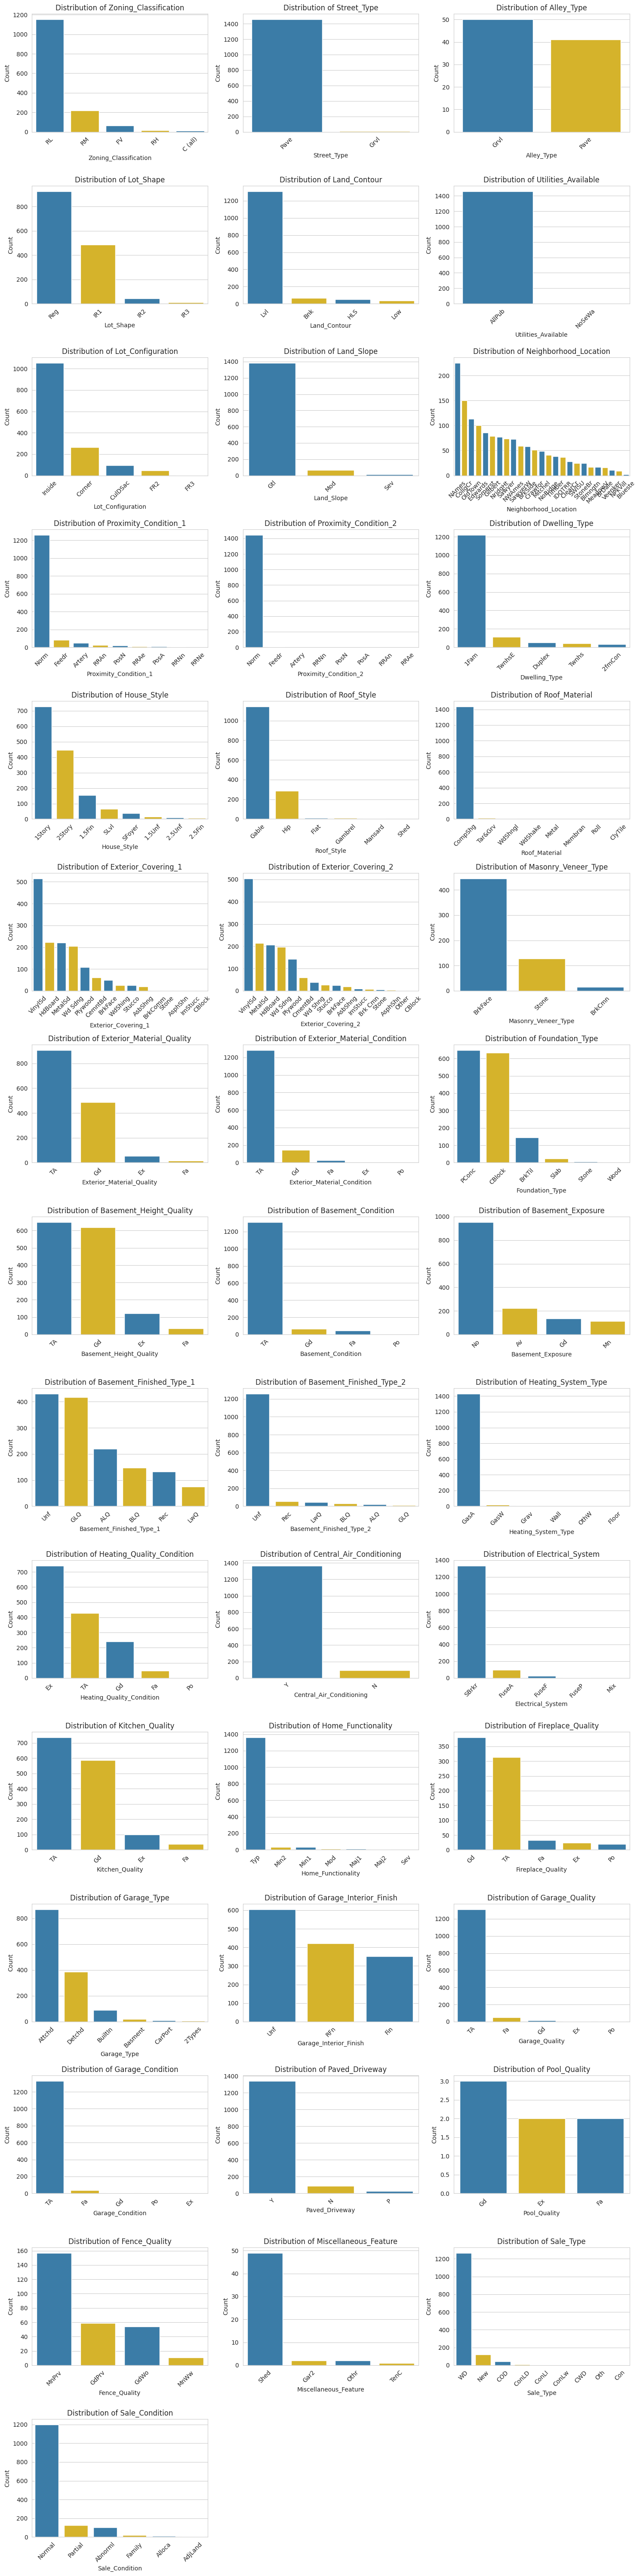

In [16]:
import math

n_cols = len(categorical_cols)

if n_cols > 0:
    ncols = 3
    nrows = math.ceil(n_cols / ncols)
    plt.figure(figsize=(15, 4 * nrows))

    for i, col in enumerate(categorical_cols, 1):
        plt.subplot(nrows, ncols, i)
        sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette=['#2980b9', '#f1c40f'])
        plt.title(f'Distribution of {col}')
        plt.xticks(rotation=45)
        plt.xlabel(col)
        plt.ylabel('Count')

    plt.tight_layout()
    plt.show()
else:
    print("No categorical columns found.")

In [17]:
ordinal_features = [
    'Basement_Condition', 'Basement_Exposure', 'Basement_Height_Quality',
    'Exterior_Material_Condition', 'Exterior_Material_Quality', 'Fence_Quality',
    'Fireplace_Quality', 'Garage_Condition', 'Garage_Quality',
    'Heating_Quality_Condition', 'Kitchen_Quality', 'Pool_Quality',
    'Basement_Finished_Type_1', 'Basement_Finished_Type_2', 'Garage_Interior_Finish',
    'Home_Functionality', 'Land_Slope', 'Lot_Shape', 'Paved_Driveway'
]

all_categorical_features = df.select_dtypes(include=['object', 'category']).columns.tolist()
nominal_features = [col for col in all_categorical_features if col not in ordinal_features]

print(f"Number of ordinal columns: {len(ordinal_features)}")
print(*ordinal_features, sep='\n')
print("=" * 50)
print(f"Number of nominal columns: {len(nominal_features)}")
print(*nominal_features, sep='\n')

Number of ordinal columns: 19
Basement_Condition
Basement_Exposure
Basement_Height_Quality
Exterior_Material_Condition
Exterior_Material_Quality
Fence_Quality
Fireplace_Quality
Garage_Condition
Garage_Quality
Heating_Quality_Condition
Kitchen_Quality
Pool_Quality
Basement_Finished_Type_1
Basement_Finished_Type_2
Garage_Interior_Finish
Home_Functionality
Land_Slope
Lot_Shape
Paved_Driveway
Number of nominal columns: 24
Zoning_Classification
Street_Type
Alley_Type
Land_Contour
Utilities_Available
Lot_Configuration
Neighborhood_Location
Proximity_Condition_1
Proximity_Condition_2
Dwelling_Type
House_Style
Roof_Style
Roof_Material
Exterior_Covering_1
Exterior_Covering_2
Masonry_Veneer_Type
Foundation_Type
Heating_System_Type
Central_Air_Conditioning
Electrical_System
Garage_Type
Miscellaneous_Feature
Sale_Type
Sale_Condition


In [18]:
ordinal_mappings = {
    'Basement_Condition': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'Basement_Height_Quality': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'Exterior_Material_Condition': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'Exterior_Material_Quality': ['Fa', 'TA', 'Gd', 'Ex'],
    'Fireplace_Quality': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'Garage_Condition': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'Garage_Quality': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'Heating_Quality_Condition': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'Kitchen_Quality': ['Fa', 'TA', 'Gd', 'Ex'],
    'Pool_Quality': ['Fa', 'Gd', 'Ex'],
    'Basement_Exposure': ['No', 'Mn', 'Av', 'Gd'],
    'Basement_Finished_Type_1': ['Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'Basement_Finished_Type_2': ['Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'Garage_Interior_Finish': ['Unf', 'RFn', 'Fin'],
    'Home_Functionality': ['Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'],
    'Land_Slope': ['Sev', 'Mod', 'Gtl'],
    'Lot_Shape': ['IR3', 'IR2', 'IR1', 'Reg'],
    'Paved_Driveway': ['N', 'P', 'Y'],
    'Fence_Quality': ['MnWw', 'GdWo', 'MnPrv', 'GdPrv']
}

## 1.3 Feature Types & Ordinal Abbreviations

### Numerical Features
Continuous or discrete numeric values (areas, years, counts, etc.).

### Nominal Categorical Features
Categories with **no inherent order** (e.g. Neighborhood, Roof Style, Foundation Type).  
→ Will be **One-Hot Encoded**.

### Ordinal Categorical Features
Categories with a **clear order / ranking**.  
→ Will be **Ordinally Encoded** so the model understands the ranking.

### Meaning of Ordinal Abbreviations

Most quality / condition features use this scale (from worst to best):

| Abbreviation | Meaning |
|--------------|---------|
| Po | Poor |
| Fa | Fair |
| TA | Typical / Average |
| Gd | Good |
| Ex | Excellent |

**Basement Exposure** (from least to most exposure):
- `No` = No Exposure
- `Mn` = Minimum Exposure
- `Av` = Average Exposure
- `Gd` = Good Exposure

**Basement Finished Type** (from worst to best):
- `Unf` = Unfinished
- `LwQ` = Low Quality
- `Rec` = Average Rec Room
- `BLQ` = Below Average Living Quarters
- `ALQ` = Average Living Quarters
- `GLQ` = Good Living Quarters

**Garage Interior Finish**:
- `Unf` = Unfinished
- `RFn` = Rough Finished
- `Fin` = Finished

**Land Slope**:
- `Gtl` = Gentle slope
- `Mod` = Moderate slope
- `Sev` = Severe slope

**Lot Shape**:
- `Reg` = Regular
- `IR1` = Slightly irregular
- `IR2` = Moderately irregular
- `IR3` = Irregular

**Paved Driveway**:
- `N` = Dirt / Gravel
- `P` = Partial Pavement
- `Y` = Paved

**Home Functionality** (from worst to best):
- `Sal` = Salvage only
- `Sev` = Severely Damaged
- `Maj2` / `Maj1` = Major Deductions
- `Mod` = Moderate Deductions
- `Min2` / `Min1` = Minor Deductions
- `Typ` = Typical Functionality

In [19]:
print("TARGET VARIABLE")
print("="*20)
print("Sale_Price : The property's sale price in dollars. This is the target variable we want to predict.")

TARGET VARIABLE
Sale_Price : The property's sale price in dollars. This is the target variable we want to predict.


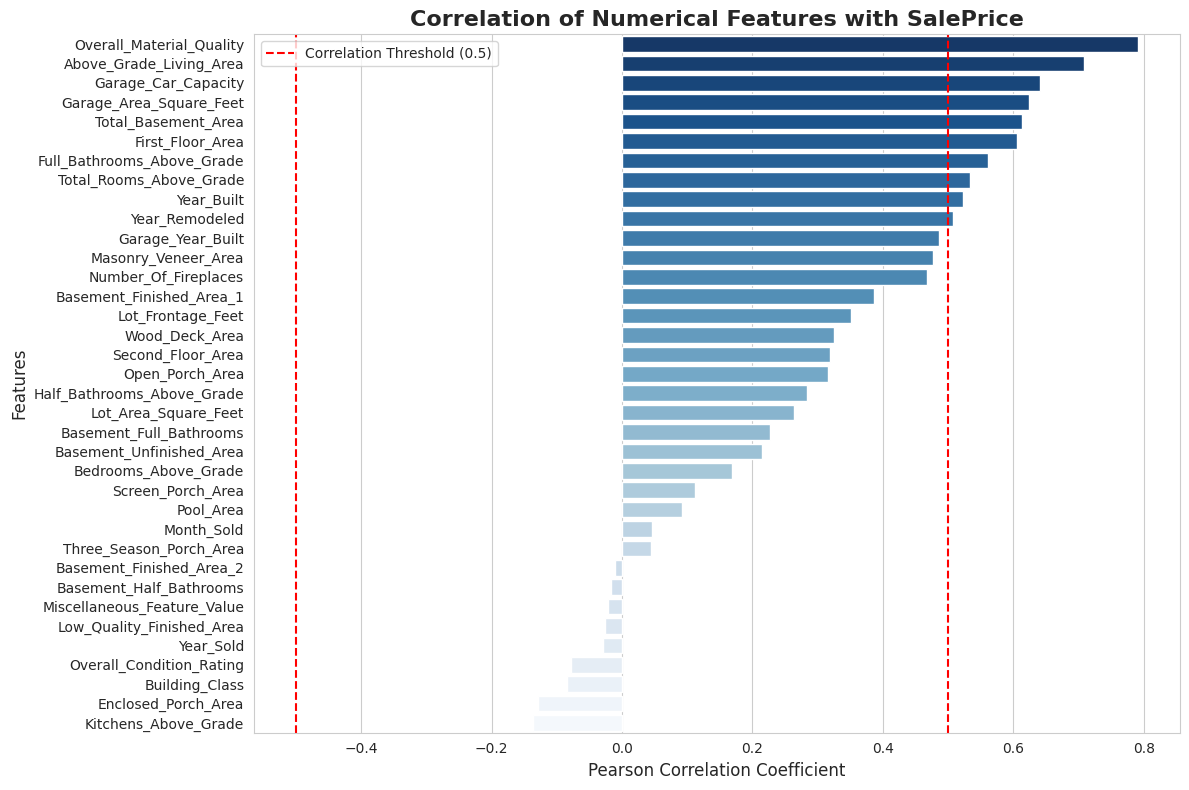

In [20]:
correlations = df[numerical_features].corr()['Sale_Price'].sort_values(ascending=False)

important_corr = correlations[correlations.index != 'Sale_Price']

plt.figure(figsize=(12, 8))
sns.barplot(x=important_corr.values, y=important_corr.index, palette='Blues_r', hue=important_corr.index, legend=False)
plt.title('Correlation of Numerical Features with SalePrice', fontsize=16, fontweight='bold')
plt.xlabel('Pearson Correlation Coefficient', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.axvline(x=0.5, color='r', linestyle='--', label='Correlation Threshold (0.5)')
plt.axvline(x=-0.5, color='r', linestyle='--')
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
correlation_threshold = 0.2
important_features = correlations[correlations >= correlation_threshold].index.tolist()
if 'Sale_Price' in important_features:
    important_features.remove('Sale_Price')

print(f" Impotant Numerical features ")
print("="*40)
for feature in important_features:
    corr_value = correlations[feature]
    print(f"- {feature:<15} : Correlation = {corr_value:.4f}")

 Impotant Numerical features 
- Overall_Material_Quality : Correlation = 0.7910
- Above_Grade_Living_Area : Correlation = 0.7086
- Garage_Car_Capacity : Correlation = 0.6404
- Garage_Area_Square_Feet : Correlation = 0.6234
- Total_Basement_Area : Correlation = 0.6136
- First_Floor_Area : Correlation = 0.6059
- Full_Bathrooms_Above_Grade : Correlation = 0.5607
- Total_Rooms_Above_Grade : Correlation = 0.5337
- Year_Built      : Correlation = 0.5229
- Year_Remodeled  : Correlation = 0.5071
- Garage_Year_Built : Correlation = 0.4864
- Masonry_Veneer_Area : Correlation = 0.4775
- Number_Of_Fireplaces : Correlation = 0.4669
- Basement_Finished_Area_1 : Correlation = 0.3864
- Lot_Frontage_Feet : Correlation = 0.3518
- Wood_Deck_Area  : Correlation = 0.3244
- Second_Floor_Area : Correlation = 0.3193
- Open_Porch_Area : Correlation = 0.3159
- Half_Bathrooms_Above_Grade : Correlation = 0.2841
- Lot_Area_Square_Feet : Correlation = 0.2638
- Basement_Full_Bathrooms : Correlation = 0.2271
- Baseme

# 2. Exploratory Data Analysis (EDA)

In this section I explore the distributions, relationships, outliers, and correlations in the data using Pandas, Matplotlib, and Seaborn.

The goal is not only to produce plots, but also to **understand the important patterns** that will later guide feature engineering and model choice.

In [22]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Building_Class,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
Lot_Frontage_Feet,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
Lot_Area_Square_Feet,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
Overall_Material_Quality,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
Overall_Condition_Rating,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
Year_Built,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
Year_Remodeled,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
Masonry_Veneer_Area,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
Basement_Finished_Area_1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0
Basement_Finished_Area_2,1460.0,46.549315,161.319273,0.0,0.00,0.0,0.00,1474.0


In [23]:
df.describe(include='object').T

,count,unique,top,freq
Zoning_Classification,1460,5,RL,1151
Street_Type,1460,2,Pave,1454
Alley_Type,91,2,Grvl,50
Lot_Shape,1460,4,Reg,925
Land_Contour,1460,4,Lvl,1311
Utilities_Available,1460,2,AllPub,1459
Lot_Configuration,1460,5,Inside,1052
Land_Slope,1460,3,Gtl,1382
Neighborhood_Location,1460,25,NAmes,225
Proximity_Condition_1,1460,9,Norm,1260


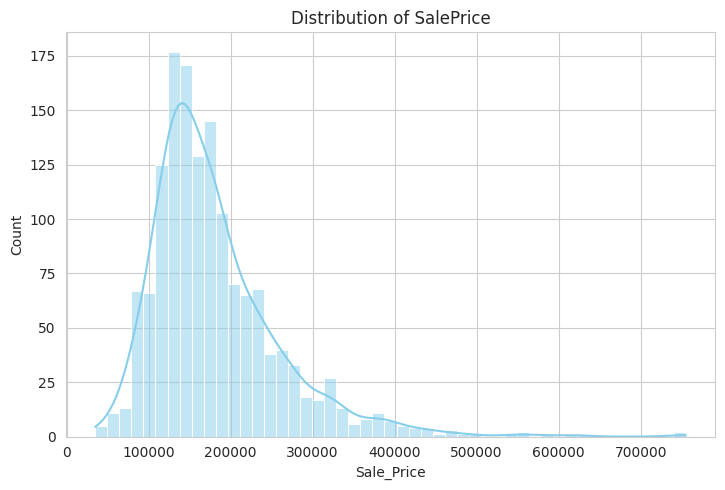

In [24]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['Sale_Price'], kde=True, color='skyblue')
plt.title('Distribution of SalePrice')
plt.xlabel('Sale_Price')

plt.tight_layout()
plt.show()

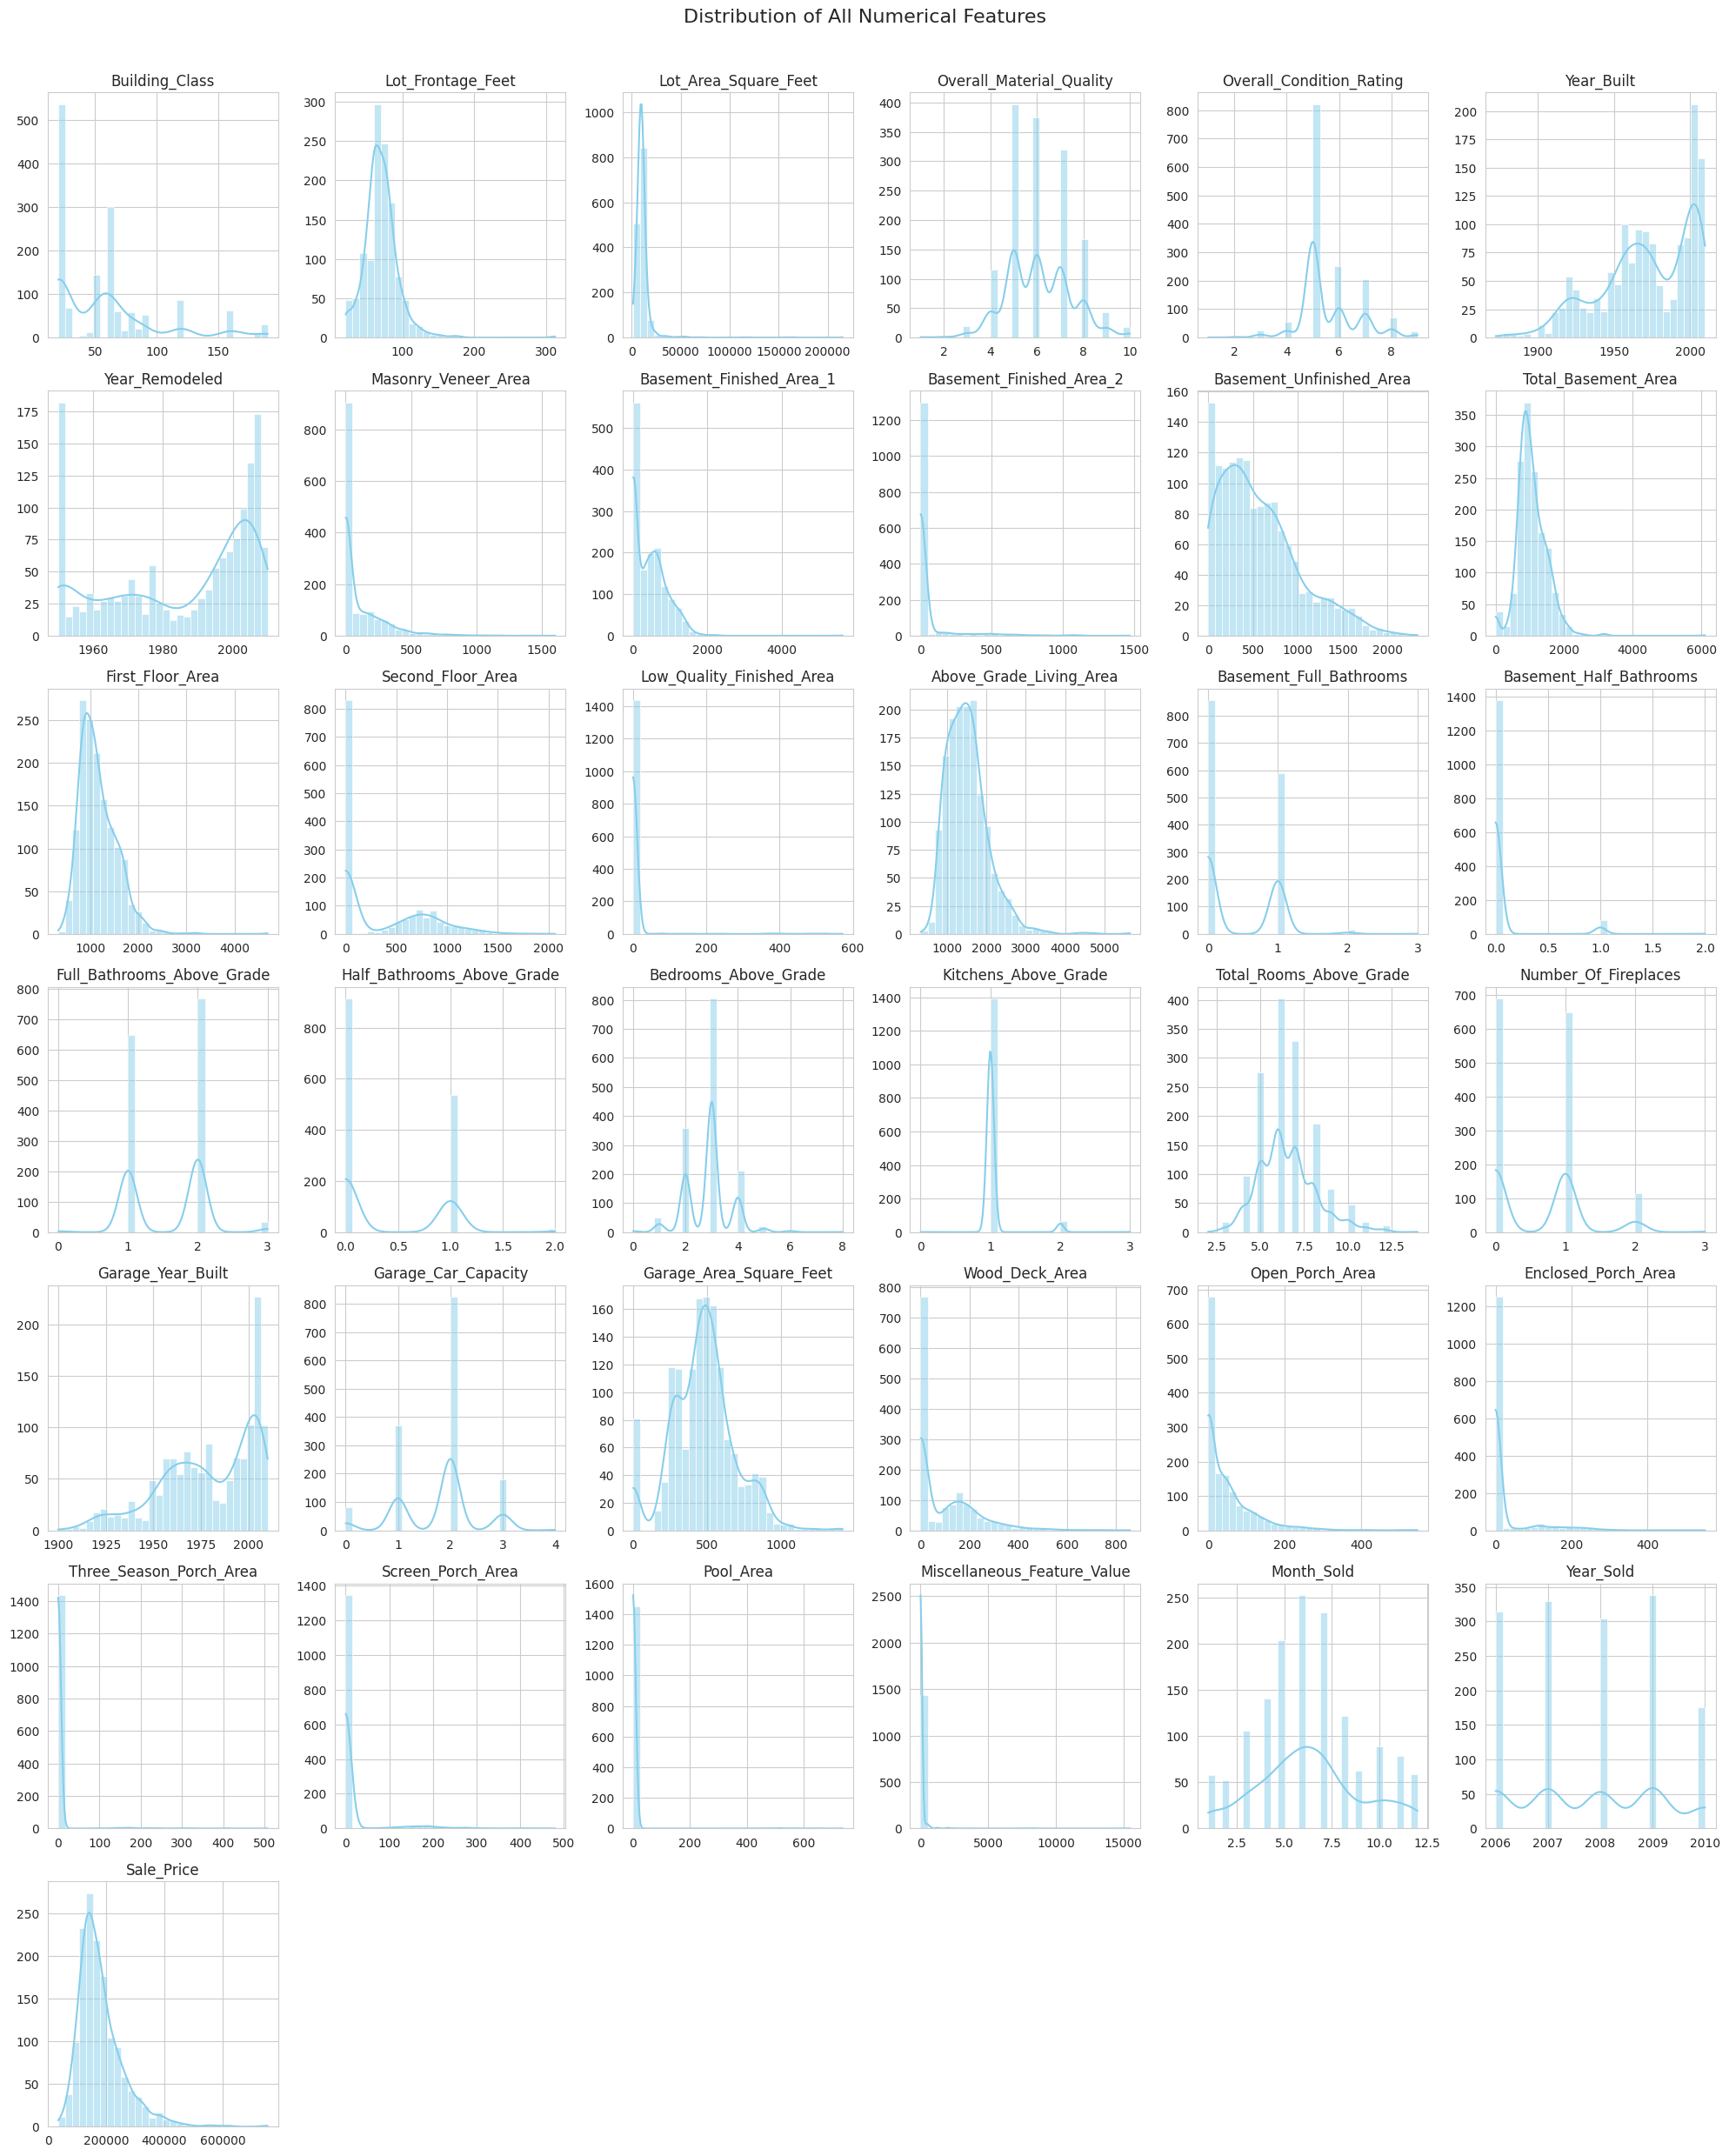

In [25]:
n_cols = 6
n_features = len(numerical_features)
n_rows = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3.5))
axes = axes.flatten()

for i, col in enumerate(numerical_features):
    sns.histplot(df[col], kde=True, color='skyblue', bins=30, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Distribution of All Numerical Features', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

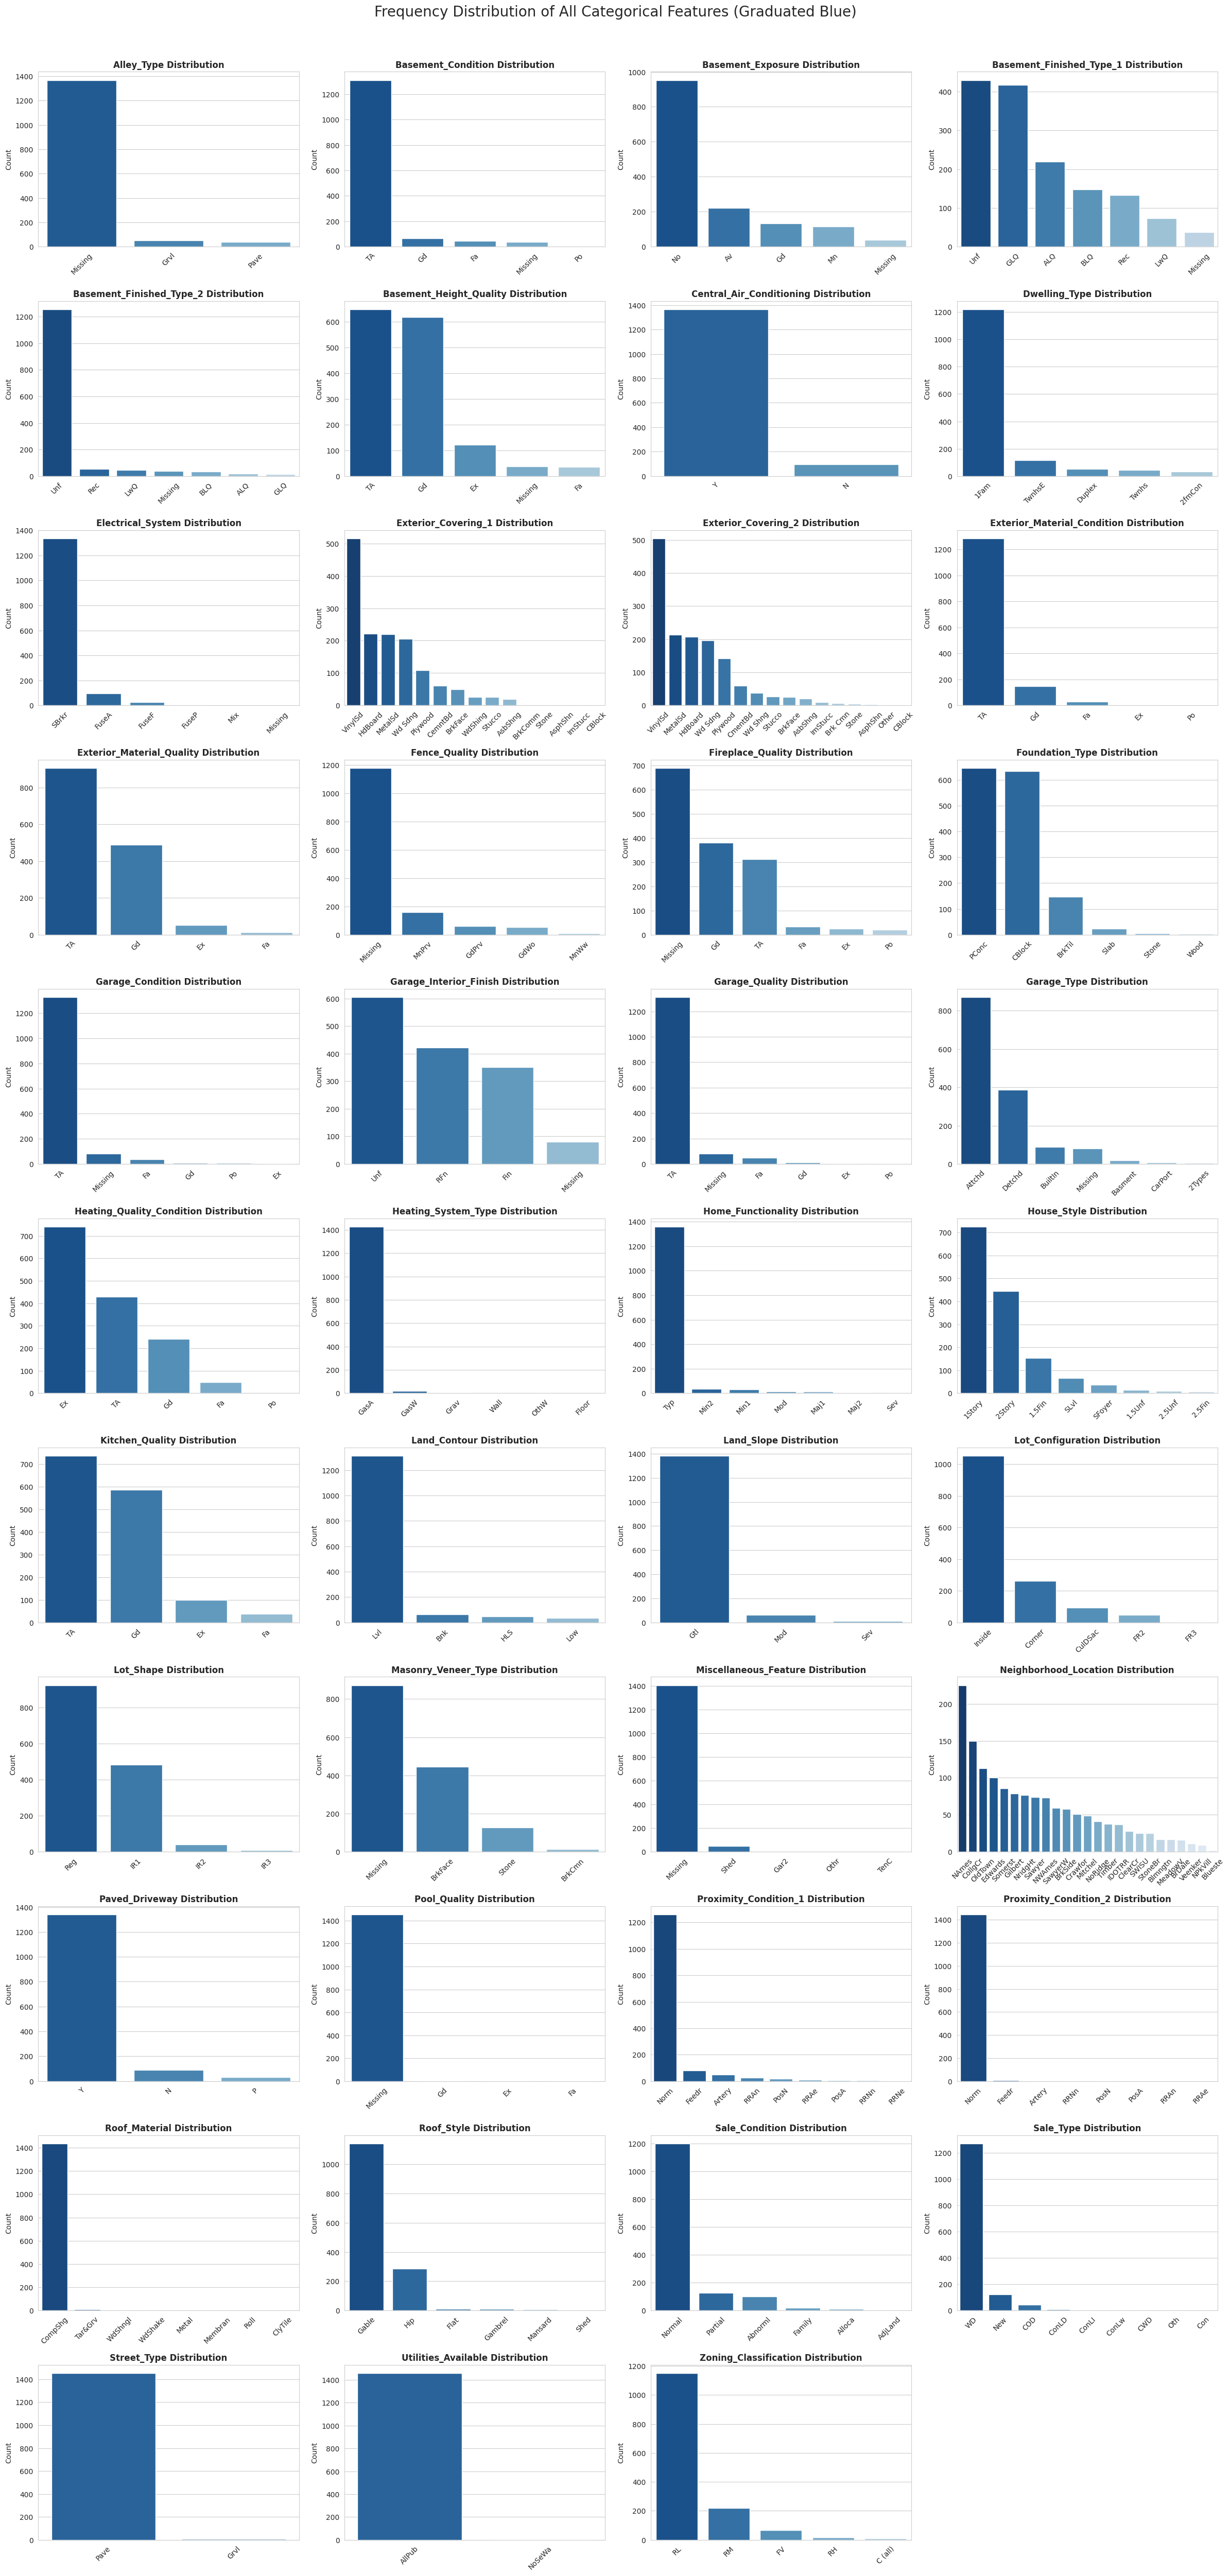

In [26]:
n_cols = 4
n_features = len(categorical_cols)
n_rows = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(24, n_rows * 4.5))
axes = axes.flatten()

for i, col in enumerate(sorted(categorical_cols)):
    val_counts = df[col].fillna('Missing').value_counts()

    blue_palette = sns.color_palette("Blues_r", n_colors=len(val_counts) + 2)[:len(val_counts)]


    sns.barplot(x=val_counts.index, y=val_counts.values, ax=axes[i], palette=blue_palette, hue=val_counts.index, legend=False)
    axes[i].set_title(f'{col} Distribution', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=45)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Frequency Distribution of All Categorical Features (Graduated Blue)', fontsize=20, y=1.01)
plt.tight_layout()
plt.show()

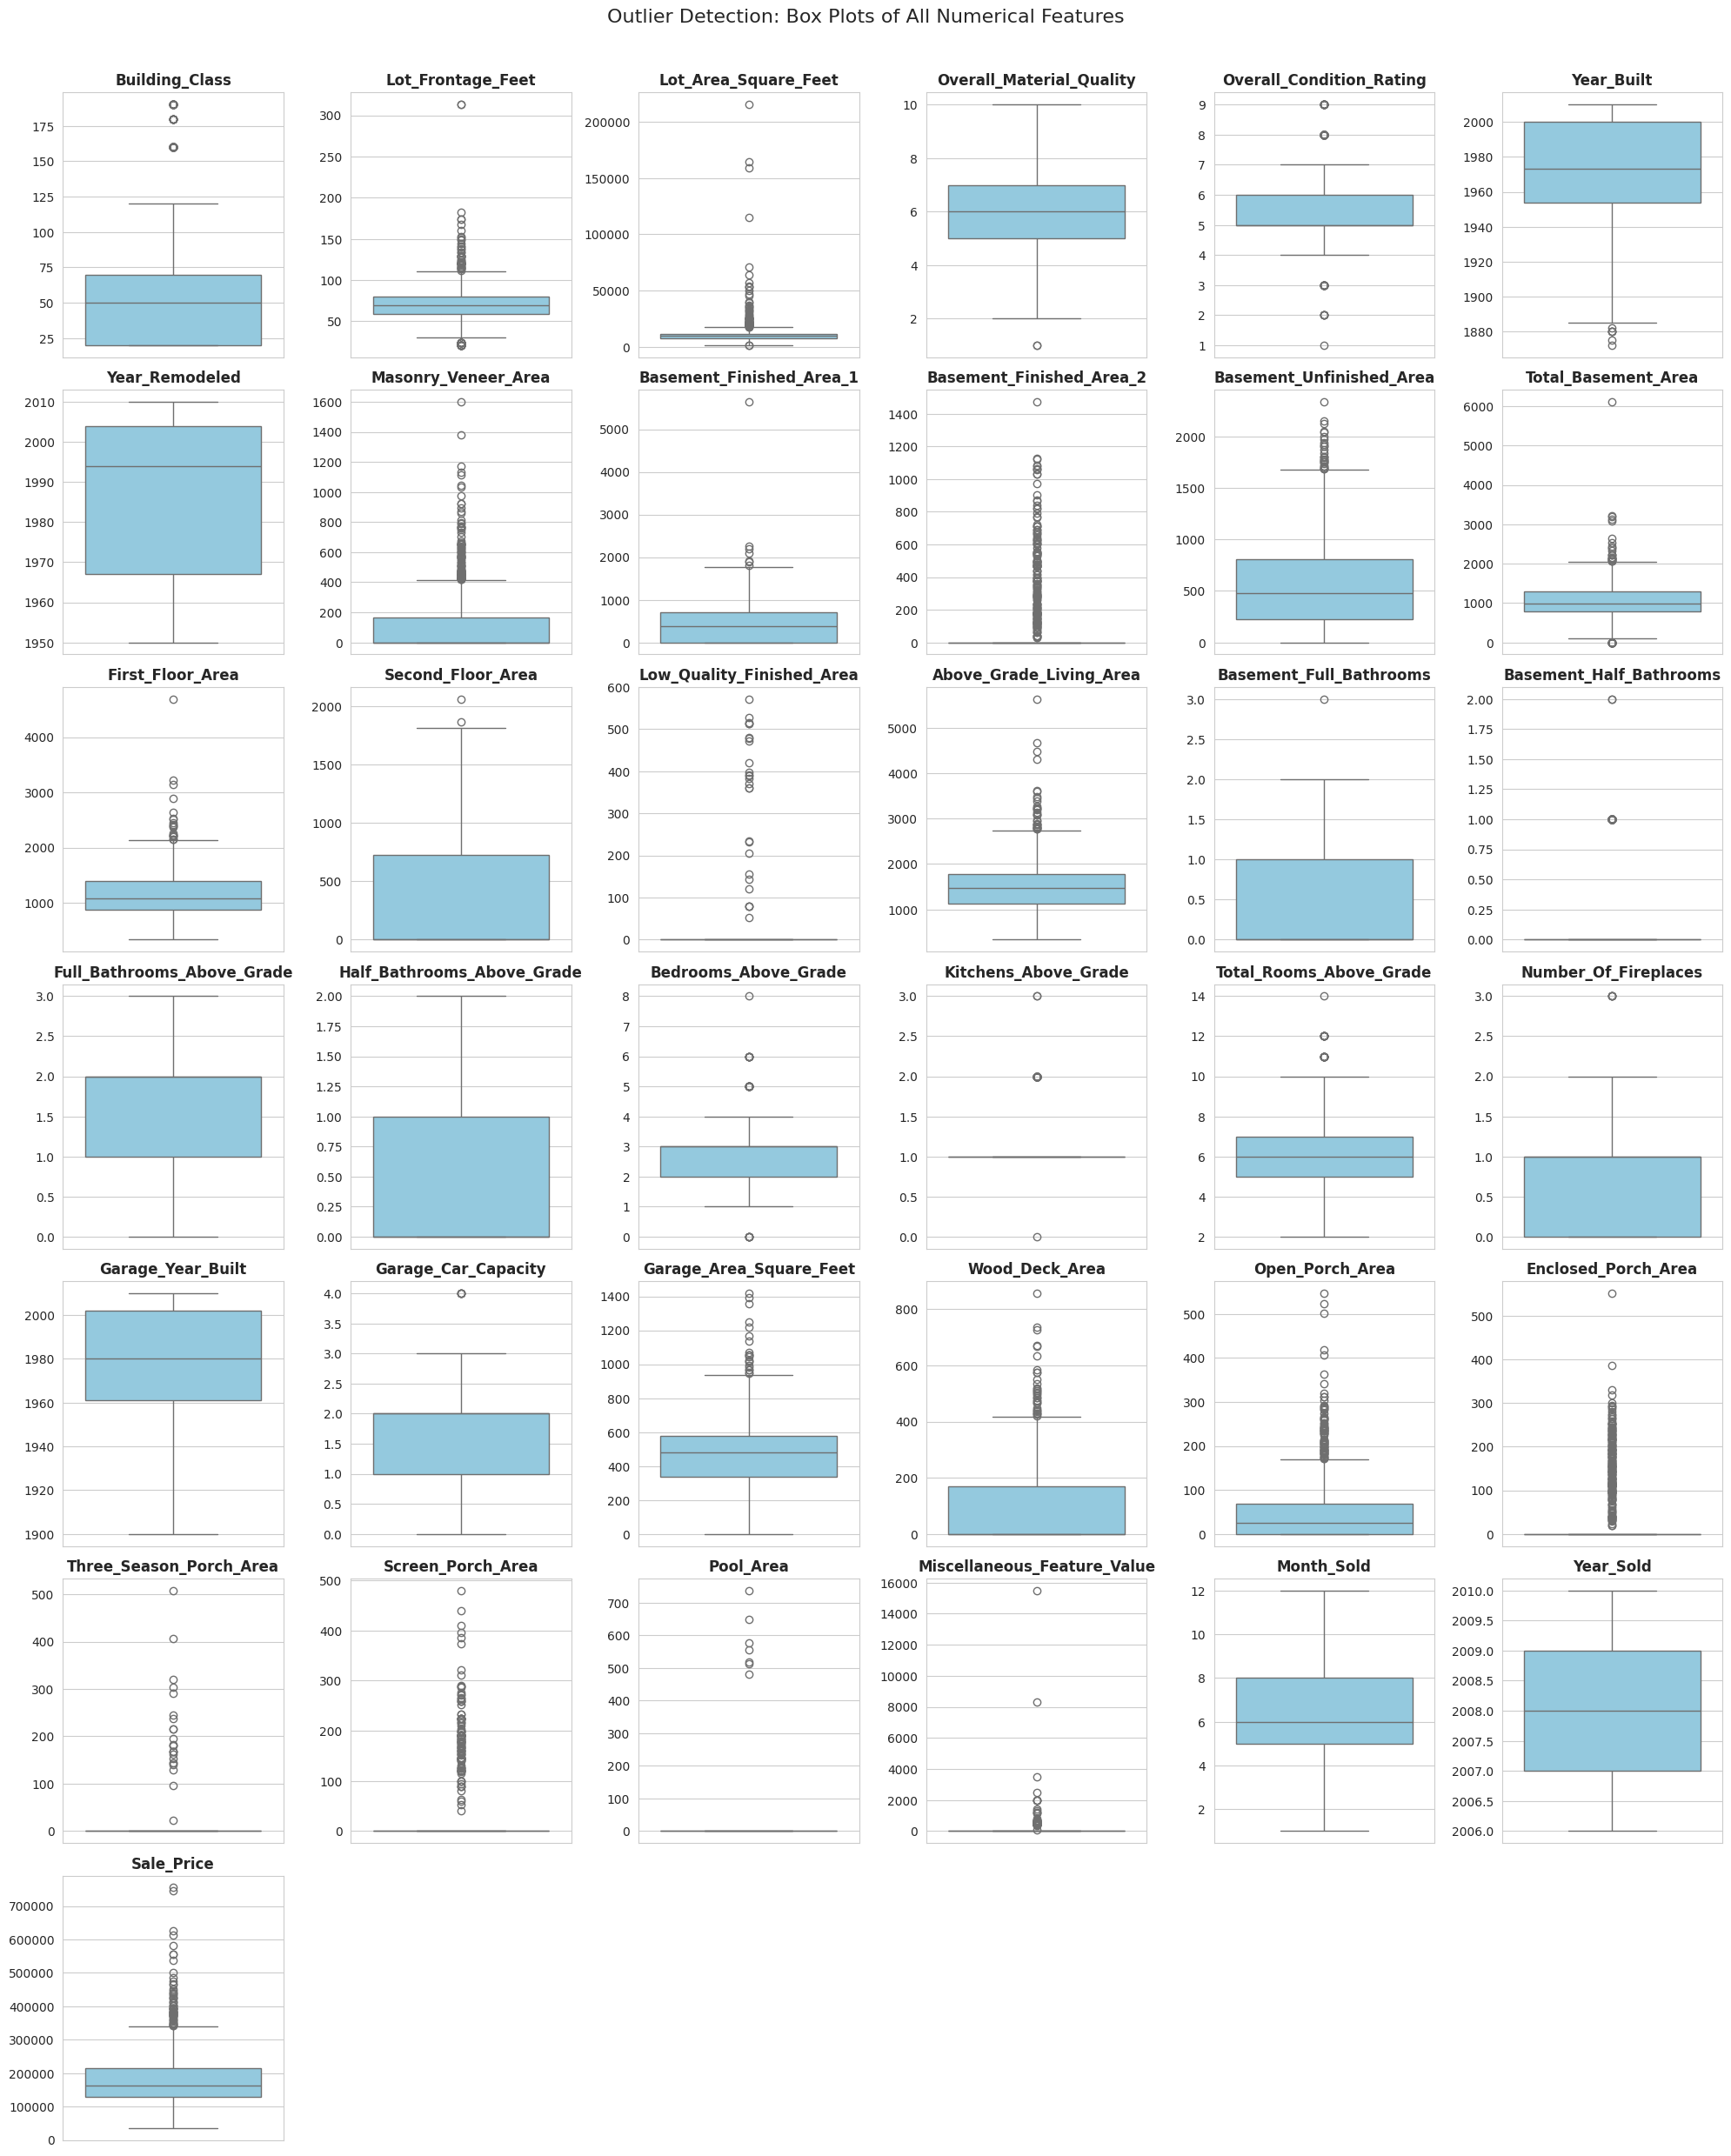

In [27]:
n_cols = 6
n_features = len(numerical_features)
n_rows = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3.5))
axes = axes.flatten()

for i, col in enumerate(numerical_features):
    # Create a boxplot for each numerical column to highlight outliers
    sns.boxplot(y=df[col], ax=axes[i], color='skyblue')
    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Outlier Detection: Box Plots of All Numerical Features', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

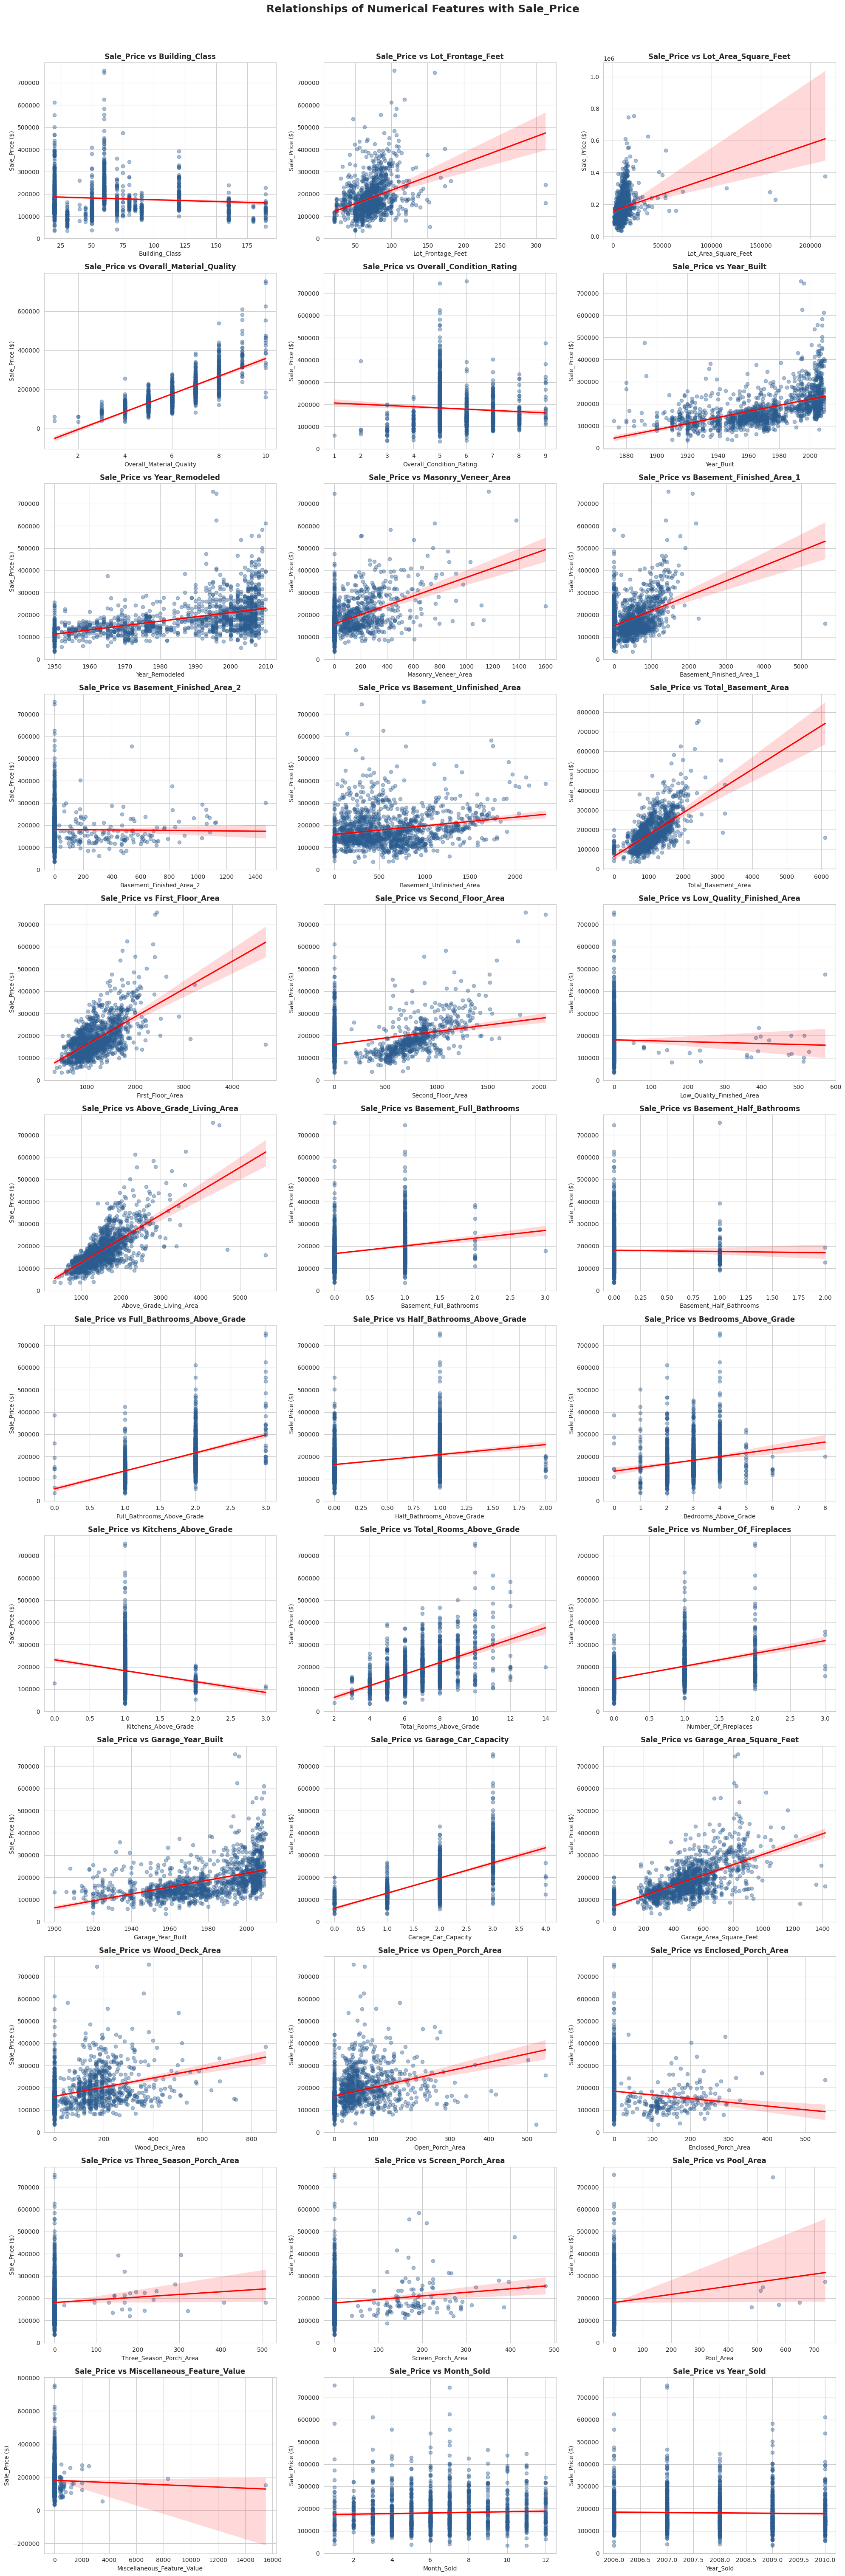

In [28]:
num_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
if 'Sale_Price' in num_features:
    num_features.remove('Sale_Price')

n_cols = 3
n_rows = (len(num_features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 5))
axes = axes.flatten()

for i, col in enumerate(num_features):
    sns.regplot(x=col, y='Sale_Price', data=df, ax=axes[i],
                scatter_kws={'alpha':0.4, 'color':'#2b5c8f'}, line_kws={'color':'red'})
    axes[i].set_title(f'Sale_Price vs {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Sale_Price ($)')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Relationships of Numerical Features with Sale_Price', fontsize=18, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

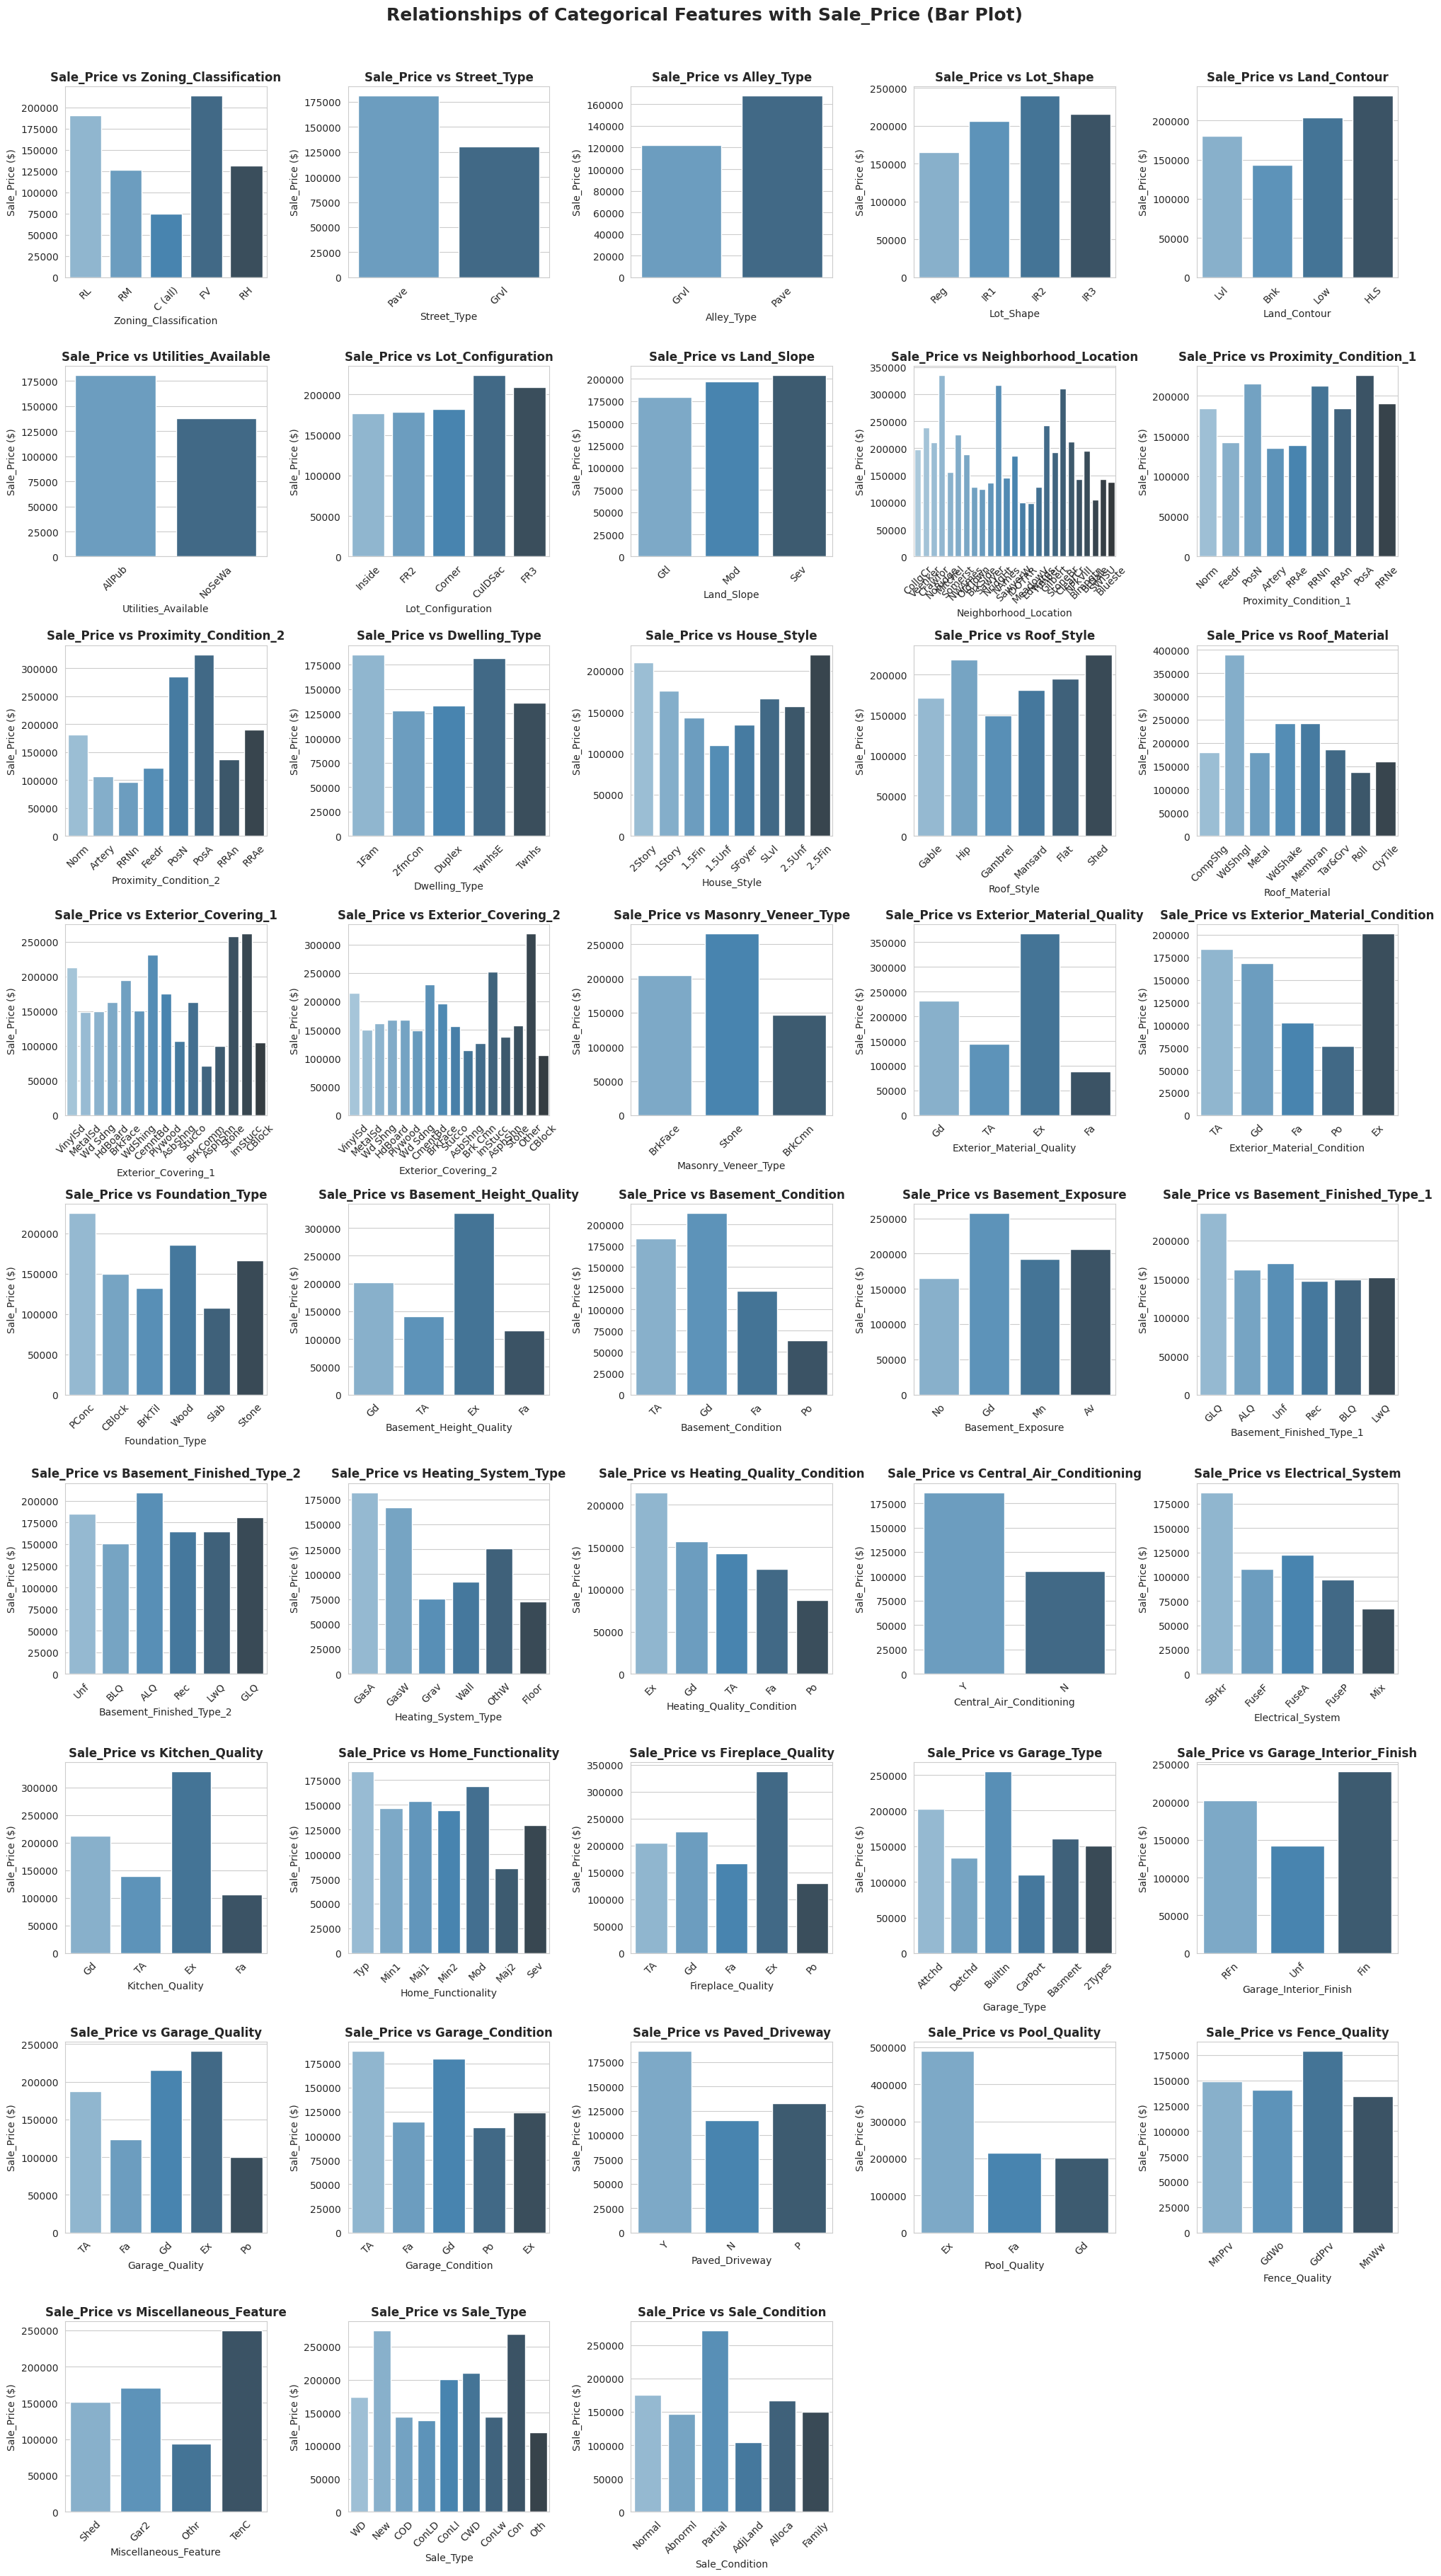

In [29]:
cat_features = df.select_dtypes(include=['object', 'category']).columns.tolist()

n_cols = 5
n_rows = (len(cat_features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    sns.barplot(x=col, y='Sale_Price', data=df, ax=axes[i], palette='Blues_d', errorbar=None)
    axes[i].set_title(f'Sale_Price vs {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Sale_Price ($)')
    axes[i].tick_params(axis='x', rotation=45)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Relationships of Categorical Features with Sale_Price (Bar Plot)', fontsize=18, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# 3. Data Analysis & Insights

In this section I investigate meaningful questions about house prices, neighborhoods, time of sale, and house characteristics.  
For every insight I follow the same structure:
1. State the question
2. Perform the analysis
3. Show a visualization (when useful)
4. Report the actual numbers
5. Explain what the result means

### Insight 1: What is the average, median, minimum, and maximum SalePrice?

In [30]:
print("Sale_Price Statistics")
print("=" * 40)
print(f"Average (Mean) : ${df['Sale_Price'].mean():,.0f}")
print(f"Median         : ${df['Sale_Price'].median():,.0f}")
print(f"Minimum        : ${df['Sale_Price'].min():,.0f}")
print(f"Maximum        : ${df['Sale_Price'].max():,.0f}")
print(f"Standard Dev.  : ${df['Sale_Price'].std():,.0f}")

Sale_Price Statistics
Average (Mean) : $180,921
Median         : $163,000
Minimum        : $34,900
Maximum        : $755,000
Standard Dev.  : $79,443


### Insight 2: Which houses have the highest and lowest sale prices?

In [31]:
# Highest priced houses
print("Top 5 most expensive houses")
print("=" * 60)
display(df.nlargest(5, 'Sale_Price')[
    ['Sale_Price', 'Neighborhood_Location', 'Overall_Material_Quality',
     'Above_Grade_Living_Area', 'Year_Built', 'Garage_Car_Capacity']
])

# Lowest priced houses
print("\nTop 5 cheapest houses")
print("=" * 60)
display(df.nsmallest(5, 'Sale_Price')[
    ['Sale_Price', 'Neighborhood_Location', 'Overall_Material_Quality',
     'Above_Grade_Living_Area', 'Year_Built', 'Garage_Car_Capacity']
])

Top 5 most expensive houses


,Sale_Price,Neighborhood_Location,Overall_Material_Quality,Above_Grade_Living_Area,Year_Built,Garage_Car_Capacity
691,755000,NoRidge,10,4316,1994,3
1182,745000,NoRidge,10,4476,1996,3
1169,625000,NoRidge,10,3627,1995,3
898,611657,NridgHt,9,2364,2009,3
803,582933,NridgHt,9,2822,2008,3



Top 5 cheapest houses


,Sale_Price,Neighborhood_Location,Overall_Material_Quality,Above_Grade_Living_Area,Year_Built,Garage_Car_Capacity
495,34900,IDOTRR,4,720,1920,0
916,35311,IDOTRR,2,480,1949,1
968,37900,OldTown,3,968,1910,0
533,39300,BrkSide,1,334,1946,0
30,40000,IDOTRR,4,1317,1920,1


### Insight 3: How does house price vary with living area (Above_Grade_Living_Area)?

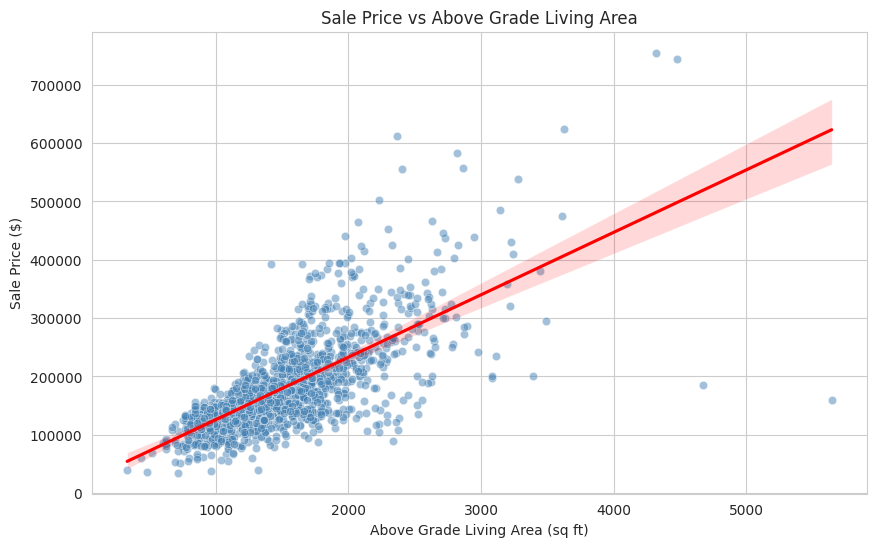

Correlation between Living Area and Sale Price: 0.709
→ Strong positive relationship: larger living area → higher price.


In [32]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Above_Grade_Living_Area', y='Sale_Price', alpha=0.5, color='steelblue')
sns.regplot(data=df, x='Above_Grade_Living_Area', y='Sale_Price', scatter=False, color='red')
plt.title('Sale Price vs Above Grade Living Area')
plt.xlabel('Above Grade Living Area (sq ft)')
plt.ylabel('Sale Price ($)')
plt.show()

corr = df['Above_Grade_Living_Area'].corr(df['Sale_Price'])
print(f"Correlation between Living Area and Sale Price: {corr:.3f}")
print("→ Strong positive relationship: larger living area → higher price.")

### Insight 4: What are the characteristics of the most expensive houses?

In [33]:
top_10 = df.nlargest(10, 'Sale_Price')

print("Average characteristics of the 10 most expensive houses:")
print("=" * 55)
print(f"Average Sale Price          : ${top_10['Sale_Price'].mean():,.0f}")
print(f"Average Overall Quality     : {top_10['Overall_Material_Quality'].mean():.1f}")
print(f"Average Living Area         : {top_10['Above_Grade_Living_Area'].mean():,.0f} sq ft")
print(f"Average Year Built          : {top_10['Year_Built'].mean():.0f}")
print(f"Average Garage Capacity     : {top_10['Garage_Car_Capacity'].mean():.1f} cars")
print(f"Most common Neighborhood    : {top_10['Neighborhood_Location'].mode()[0]}")
print(f"Average Total Basement Area : {top_10['Total_Basement_Area'].mean():,.0f} sq ft")

Average characteristics of the 10 most expensive houses:
Average Sale Price          : $595,601
Average Overall Quality     : 9.3
Average Living Area         : 3,153 sq ft
Average Year Built          : 2003
Average Garage Capacity     : 3.0 cars
Most common Neighborhood    : NridgHt
Average Total Basement Area : 2,171 sq ft


### Insight 5: Which 3 neighborhoods have the highest average house prices?

In [34]:
neigh_avg = df.groupby('Neighborhood_Location')['Sale_Price'].agg(['mean', 'count']).sort_values('mean', ascending=False)

print("Top 3 neighborhoods by average Sale Price:")
print("=" * 50)
display(neigh_avg.head(3).round(0))

top3 = neigh_avg.head(3)
print(f"\nAverage price in the top 3 neighborhoods: ${top3['mean'].mean():,.0f}")

Top 3 neighborhoods by average Sale Price:


,mean,count
Neighborhood_Location,,
NoRidge,335295.0,41
NridgHt,316271.0,77
StoneBr,310499.0,25



Average price in the top 3 neighborhoods: $320,688


### Insight 6: Which 3 neighborhoods have the lowest average house prices?

In [35]:
print("Bottom 3 neighborhoods by average Sale Price:")
print("=" * 50)
display(neigh_avg.tail(3).round(0))

bottom3 = neigh_avg.tail(3)
print(f"\nAverage price in the lowest 3 neighborhoods: ${bottom3['mean'].mean():,.0f}")

Bottom 3 neighborhoods by average Sale Price:


,mean,count
Neighborhood_Location,,
BrDale,104494.0,16
IDOTRR,100124.0,37
MeadowV,98576.0,17



Average price in the lowest 3 neighborhoods: $101,065


### Insight 7: Which neighborhood has the highest number of houses?  
Does neighborhood appear to have a strong relationship with house price?

Neighborhood with the highest number of houses:
                            mean  count
Neighborhood_Location                  
NAmes                  145847.08    225


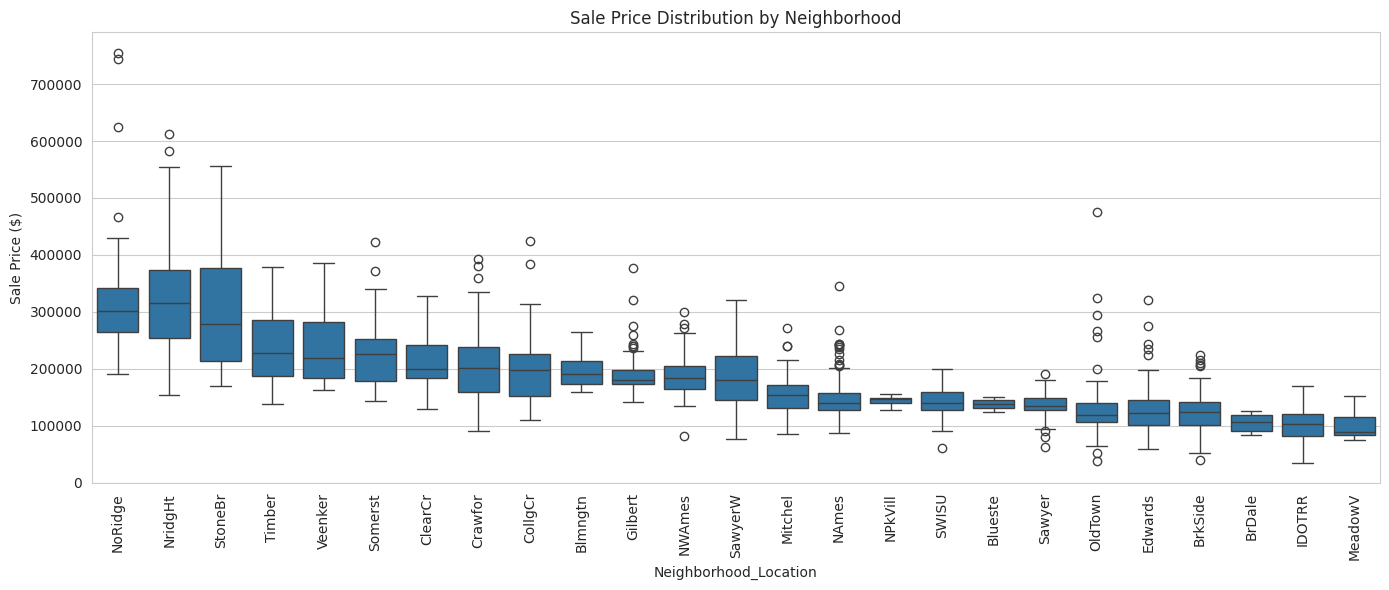


→ Yes, neighborhood has a strong relationship with price.
  The boxplot shows clear differences between neighborhoods.
  The most expensive neighborhood is about 3.4x more expensive than the cheapest one.


In [36]:
print("Neighborhood with the highest number of houses:")
print("=" * 50)
print(neigh_avg.sort_values('count', ascending=False).head(1))

# Visualization
plt.figure(figsize=(14, 6))
order = neigh_avg.index
sns.boxplot(data=df, x='Neighborhood_Location', y='Sale_Price', order=order)
plt.xticks(rotation=90)
plt.title('Sale Price Distribution by Neighborhood')
plt.ylabel('Sale Price ($)')
plt.tight_layout()
plt.show()

print("\n→ Yes, neighborhood has a strong relationship with price.")
print("  The boxplot shows clear differences between neighborhoods.")
print(f"  The most expensive neighborhood is about {neigh_avg['mean'].iloc[0]/neigh_avg['mean'].iloc[-1]:.1f}x more expensive than the cheapest one.")

### Insight 8: Which month has the highest and lowest average house sale price?

In [37]:
month_avg = df.groupby('Month_Sold')['Sale_Price'].mean().sort_values(ascending=False)

print("Average Sale Price by Month:")
print("=" * 40)
display(month_avg.round(0))

print(f"\nHighest average price month : Month {month_avg.index[0]} → ${month_avg.iloc[0]:,.0f}")
print(f"Lowest average price month  : Month {month_avg.index[-1]} → ${month_avg.iloc[-1]:,.0f}")

Average Sale Price by Month:


,Sale_Price
Month_Sold,
9,195683.0
11,192211.0
12,186519.0
7,186331.0
8,184652.0
1,183256.0
3,183254.0
10,179564.0
2,177882.0



Highest average price month : Month 9 → $195,683
Lowest average price month  : Month 4 → $171,503


### Insight 9: Which month has the highest number of house sales?  
Does the average house price vary throughout the year?

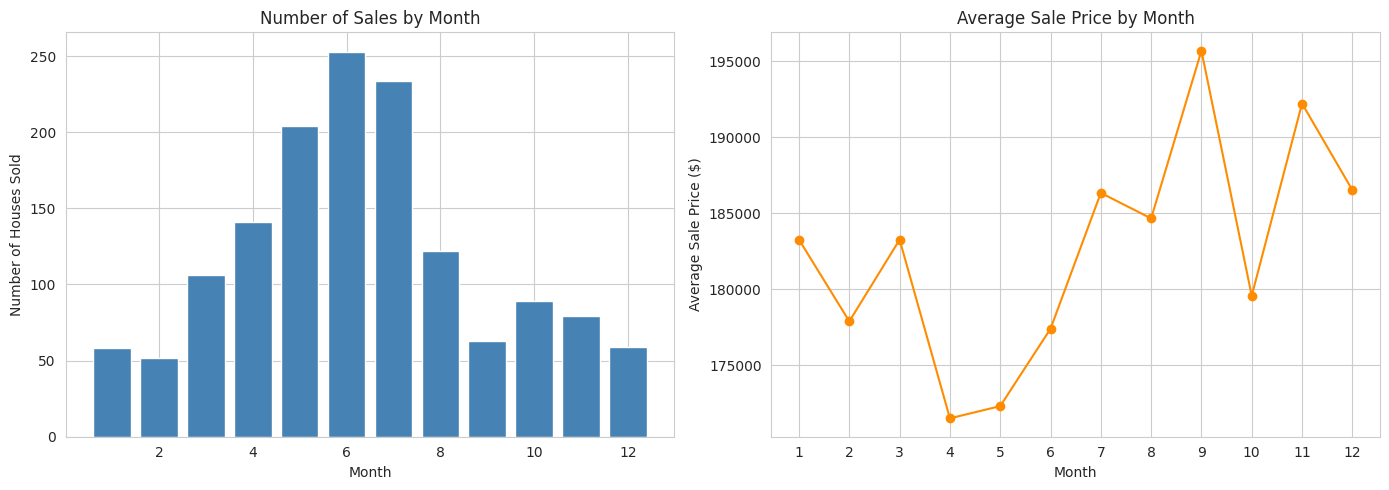

Month with most sales: Month 6 (253 houses)
Price variation (max - min): $24,180
→ There is some variation across months, but it is not extremely large.


In [38]:
month_counts = df['Month_Sold'].value_counts().sort_index()
month_price = df.groupby('Month_Sold')['Sale_Price'].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(month_counts.index, month_counts.values, color='steelblue')
axes[0].set_title('Number of Sales by Month')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Number of Houses Sold')

axes[1].plot(month_price.index, month_price.values, marker='o', color='darkorange')
axes[1].set_title('Average Sale Price by Month')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Average Sale Price ($)')
axes[1].set_xticks(range(1, 13))

plt.tight_layout()
plt.show()

print(f"Month with most sales: Month {month_counts.idxmax()} ({month_counts.max()} houses)")
print(f"Price variation (max - min): ${month_price.max() - month_price.min():,.0f}")
print("→ There is some variation across months, but it is not extremely large.")

### Insight 10: Does the number of bedrooms affect house price?

Average Sale Price by Number of Bedrooms:


,mean,count
Bedrooms_Above_Grade,,
0,221493.0,6
1,173162.0,50
2,158198.0,358
3,181057.0,804
4,220421.0,213
5,180819.0,21
6,143779.0,7
8,200000.0,1


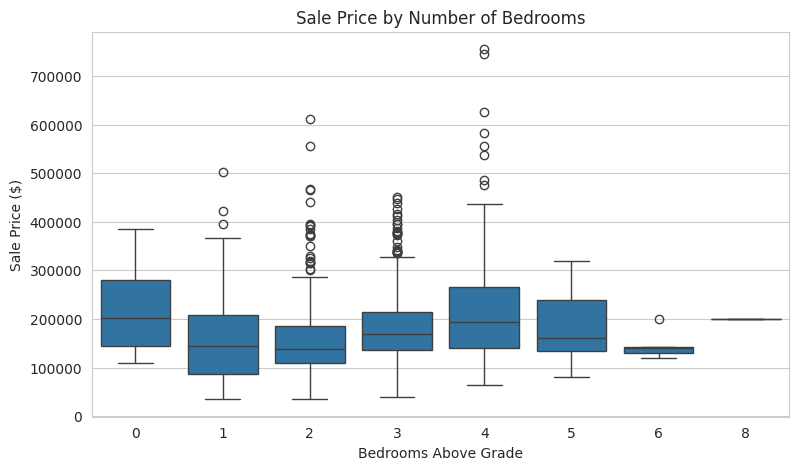

→ Price generally increases with more bedrooms up to 4, then the relationship becomes weaker / less clear.


In [39]:
bed_price = df.groupby('Bedrooms_Above_Grade')['Sale_Price'].agg(['mean', 'count'])
print("Average Sale Price by Number of Bedrooms:")
print("=" * 45)
display(bed_price.round(0))

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='Bedrooms_Above_Grade', y='Sale_Price')
plt.title('Sale Price by Number of Bedrooms')
plt.xlabel('Bedrooms Above Grade')
plt.ylabel('Sale Price ($)')
plt.show()

print("→ Price generally increases with more bedrooms up to 4, then the relationship becomes weaker / less clear.")

### Insight 11: How does the number of bathrooms relate to SalePrice?

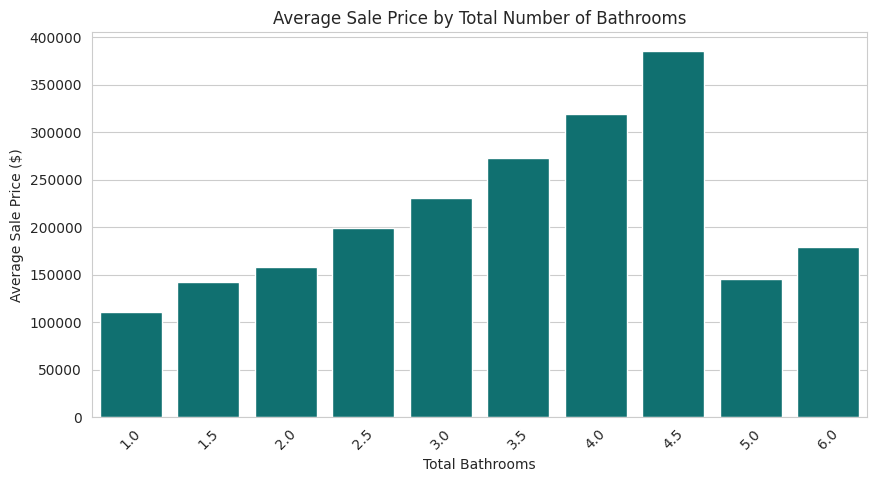

Total_Bathrooms
1.0    110870.0
1.5    142692.0
2.0    158116.0
2.5    199724.0
3.0    230526.0
3.5    273513.0
4.0    319119.0
4.5    386107.0
5.0    145900.0
6.0    179000.0
Name: Sale_Price, dtype: float64

→ Clear positive relationship: more bathrooms → higher average price.


In [40]:
# Total bathrooms = full + half (0.5) + basement full + basement half (0.5)
df['Total_Bathrooms'] = (
    df['Full_Bathrooms_Above_Grade'] +
    0.5 * df['Half_Bathrooms_Above_Grade'] +
    df['Basement_Full_Bathrooms'] +
    0.5 * df['Basement_Half_Bathrooms']
)

bath_price = df.groupby('Total_Bathrooms')['Sale_Price'].mean()

plt.figure(figsize=(10, 5))
sns.barplot(x=bath_price.index, y=bath_price.values, color='teal')
plt.title('Average Sale Price by Total Number of Bathrooms')
plt.xlabel('Total Bathrooms')
plt.ylabel('Average Sale Price ($)')
plt.xticks(rotation=45)
plt.show()

print(bath_price.round(0))
print("\n→ Clear positive relationship: more bathrooms → higher average price.")

### Insight 12: How does overall house quality (Overall_Material_Quality) affect price?

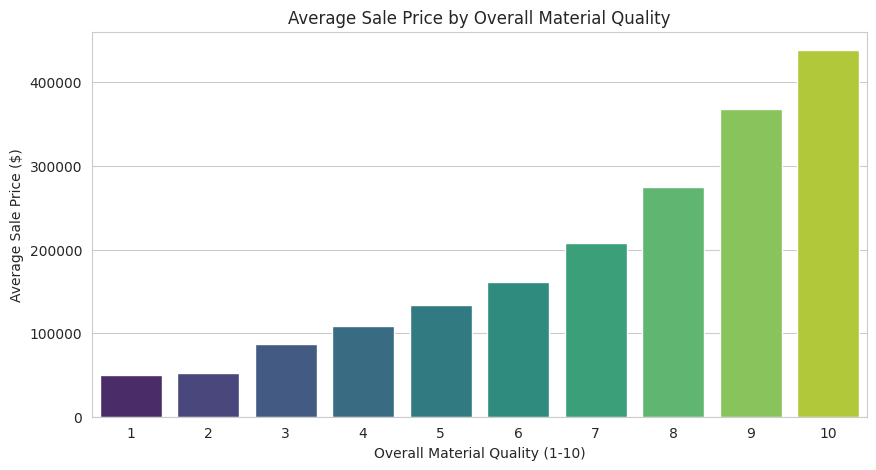

Overall_Material_Quality
1      50150.0
2      51770.0
3      87474.0
4     108421.0
5     133523.0
6     161603.0
7     207716.0
8     274736.0
9     367513.0
10    438588.0
Name: Sale_Price, dtype: float64

Correlation with Sale_Price: 0.791
→ One of the strongest predictors. Higher quality → much higher price.


In [41]:
qual_price = df.groupby('Overall_Material_Quality')['Sale_Price'].mean()

plt.figure(figsize=(10, 5))
sns.barplot(x=qual_price.index, y=qual_price.values, palette='viridis')
plt.title('Average Sale Price by Overall Material Quality')
plt.xlabel('Overall Material Quality (1-10)')
plt.ylabel('Average Sale Price ($)')
plt.show()

print(qual_price.round(0))
print(f"\nCorrelation with Sale_Price: {df['Overall_Material_Quality'].corr(df['Sale_Price']):.3f}")
print("→ One of the strongest predictors. Higher quality → much higher price.")

### Insight 13: How does garage capacity affect house price?

Average Sale Price by Garage Capacity:


,mean,count
Garage_Car_Capacity,,
0,103317.0,81
1,128117.0,369
2,183852.0,824
3,309636.0,181
4,192656.0,5


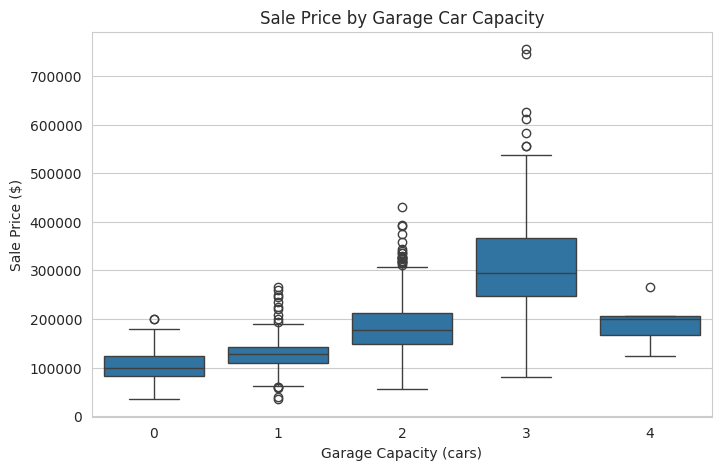

→ Houses with larger garages (especially 3 cars) have clearly higher prices.


In [42]:
garage_price = df.groupby('Garage_Car_Capacity')['Sale_Price'].agg(['mean', 'count'])
print("Average Sale Price by Garage Capacity:")
print("=" * 45)
display(garage_price.round(0))

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Garage_Car_Capacity', y='Sale_Price')
plt.title('Sale Price by Garage Car Capacity')
plt.xlabel('Garage Capacity (cars)')
plt.ylabel('Sale Price ($)')
plt.show()

print("→ Houses with larger garages (especially 3 cars) have clearly higher prices.")

### Insight 14: Does having a basement significantly affect the average house price?

Sale Price by Basement Presence:


,mean,count,median
Has_Basement,,,
Has Basement,182878.0,1423,165000.0
No Basement,105653.0,37,101800.0


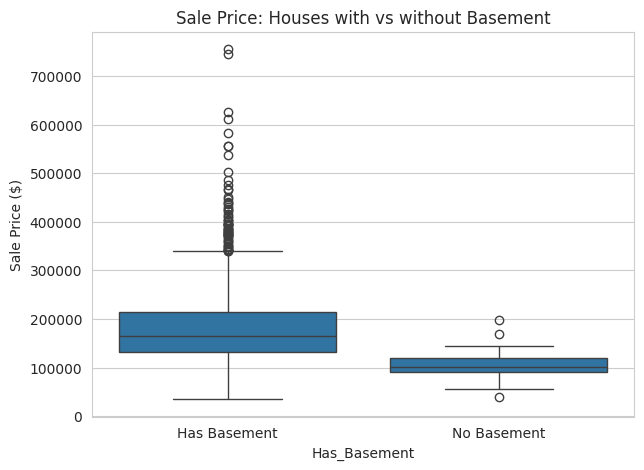


Difference in average price: $77,225
→ Yes, houses with a basement are significantly more expensive on average.


In [43]:
df['Has_Basement'] = (df['Total_Basement_Area'] > 0).map({True: 'Has Basement', False: 'No Basement'})

basement_stats = df.groupby('Has_Basement')['Sale_Price'].agg(['mean', 'count', 'median'])
print("Sale Price by Basement Presence:")
print("=" * 45)
display(basement_stats.round(0))

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='Has_Basement', y='Sale_Price')
plt.title('Sale Price: Houses with vs without Basement')
plt.ylabel('Sale Price ($)')
plt.show()

diff = basement_stats.loc['Has Basement', 'mean'] - basement_stats.loc['No Basement', 'mean']
print(f"\nDifference in average price: ${diff:,.0f}")
print("→ Yes, houses with a basement are significantly more expensive on average.")

### Insight 15: How does house age affect SalePrice?

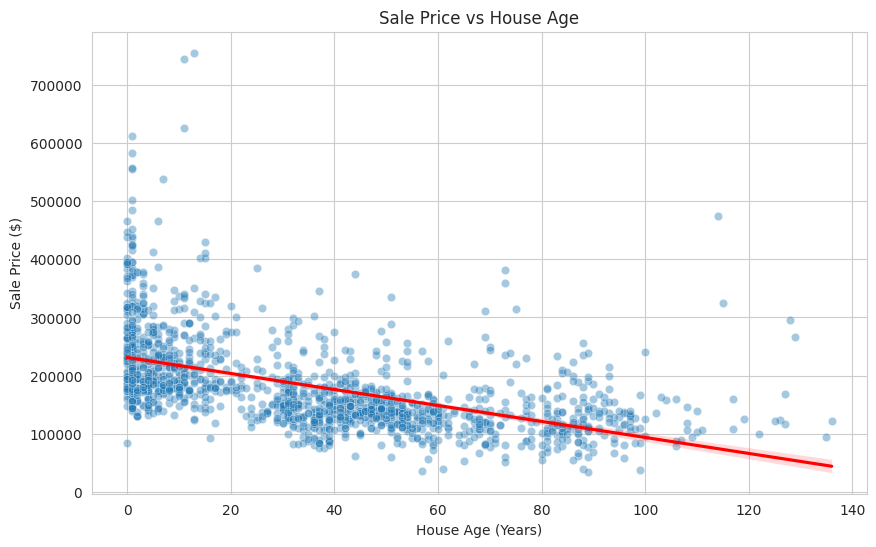

Correlation between House Age and Sale Price: -0.523
→ Negative relationship: newer houses tend to be more expensive.


In [44]:
df['House_Age'] = df['Year_Sold'] - df['Year_Built']

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='House_Age', y='Sale_Price', alpha=0.4)
sns.regplot(data=df, x='House_Age', y='Sale_Price', scatter=False, color='red')
plt.title('Sale Price vs House Age')
plt.xlabel('House Age (Years)')
plt.ylabel('Sale Price ($)')
plt.show()

corr_age = df['House_Age'].corr(df['Sale_Price'])
print(f"Correlation between House Age and Sale Price: {corr_age:.3f}")
print("→ Negative relationship: newer houses tend to be more expensive.")

### Summary of Key Insights

- Living area, overall quality, and neighborhood are among the strongest drivers of price.
- Newer houses, houses with more bathrooms, larger garages, and basements sell for higher prices.
- There is moderate seasonal variation in both number of sales and average prices.
- The most expensive houses are typically large, high-quality, and located in specific neighborhoods (e.g. NoRidge, NridgHt, StoneBr).

### Insight 16: Does having Central Air Conditioning significantly affect house price?

Sale Price by Central Air Conditioning:


,mean,median,count
Central_Air_Conditioning,,,
N,105264.0,98000.0,95
Y,186187.0,168000.0,1365


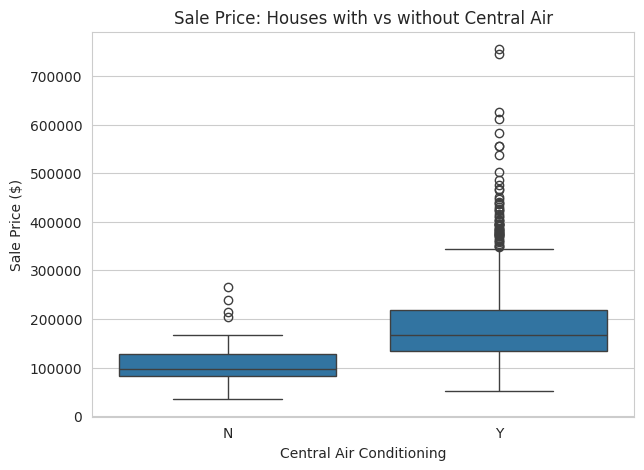


Average price difference: $80,923
→ Houses with Central Air are clearly more expensive on average.
  This makes sense because Central Air is considered a desirable modern feature.


In [45]:
air_stats = df.groupby('Central_Air_Conditioning')['Sale_Price'].agg(['mean', 'median', 'count'])
print("Sale Price by Central Air Conditioning:")
print("=" * 50)
display(air_stats.round(0))

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='Central_Air_Conditioning', y='Sale_Price', order=['N', 'Y'])
plt.title('Sale Price: Houses with vs without Central Air')
plt.xlabel('Central Air Conditioning')
plt.ylabel('Sale Price ($)')
plt.show()

diff = air_stats.loc['Y', 'mean'] - air_stats.loc['N', 'mean']
print(f"\nAverage price difference: ${diff:,.0f}")
print("→ Houses with Central Air are clearly more expensive on average.")
print("  This makes sense because Central Air is considered a desirable modern feature.")

### Insight 17: How does Kitchen Quality affect house price?

Average Sale Price by Kitchen Quality:


,Sale_Price
Kitchen_Quality,
Fa,105565.0
TA,139963.0
Gd,212116.0
Ex,328555.0


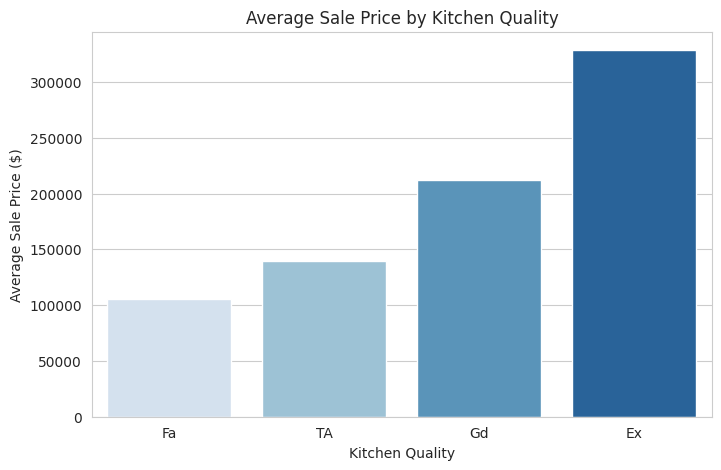


Price jump from 'TA' (Typical) to 'Ex' (Excellent): $188,592
→ Kitchen quality has a strong positive effect on price.
  Excellent kitchens command a large premium over typical ones.


In [46]:
# Order the quality levels
kitchen_order = ['Fa', 'TA', 'Gd', 'Ex']
kitchen_price = df.groupby('Kitchen_Quality')['Sale_Price'].mean().reindex(kitchen_order)

print("Average Sale Price by Kitchen Quality:")
print("=" * 45)
display(kitchen_price.round(0))

plt.figure(figsize=(8, 5))
sns.barplot(x=kitchen_price.index, y=kitchen_price.values, order=kitchen_order, palette='Blues')
plt.title('Average Sale Price by Kitchen Quality')
plt.xlabel('Kitchen Quality')
plt.ylabel('Average Sale Price ($)')
plt.show()

print(f"\nPrice jump from 'TA' (Typical) to 'Ex' (Excellent): ${kitchen_price['Ex'] - kitchen_price['TA']:,.0f}")
print("→ Kitchen quality has a strong positive effect on price.")
print("  Excellent kitchens command a large premium over typical ones.")

### Insight 18: Do recently remodeled houses sell for higher prices?

Sale Price: Remodeled vs Not Remodeled houses


,mean,median,count
Was_Remodeled,,,
Not Remodeled,182584.0,170000.0,764
Remodeled,179096.0,155000.0,696


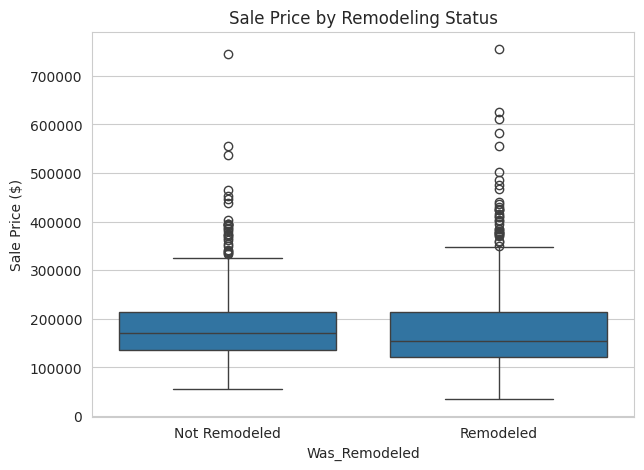


Average difference: $-3,487
→ Remodeled houses have a higher average price.
  Buyers seem to value recent improvements and updates.


In [47]:
df['Was_Remodeled'] = (df['Year_Remodeled'] != df['Year_Built']).map({True: 'Remodeled', False: 'Not Remodeled'})

remod_stats = df.groupby('Was_Remodeled')['Sale_Price'].agg(['mean', 'median', 'count'])
print("Sale Price: Remodeled vs Not Remodeled houses")
print("=" * 55)
display(remod_stats.round(0))

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='Was_Remodeled', y='Sale_Price')
plt.title('Sale Price by Remodeling Status')
plt.ylabel('Sale Price ($)')
plt.show()

diff = remod_stats.loc['Remodeled', 'mean'] - remod_stats.loc['Not Remodeled', 'mean']
print(f"\nAverage difference: ${diff:,.0f}")
print("→ Remodeled houses have a higher average price.")
print("  Buyers seem to value recent improvements and updates.")

### Insight 19: How does the number of fireplaces affect house price?


Average Sale Price by Number of Fireplaces:


,mean,count
Number_Of_Fireplaces,,
0,141331.0,690
1,211844.0,650
2,240589.0,115
3,252000.0,5


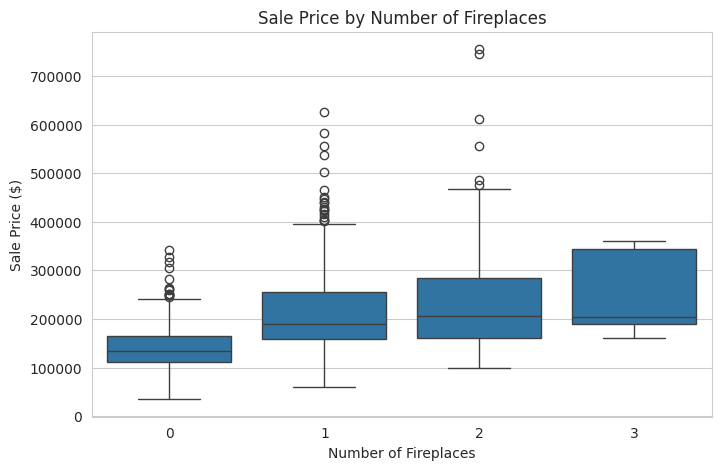

→ Houses with at least one fireplace are more expensive.
  Having 2 fireplaces shows an even higher average price, though the sample becomes smaller.


In [48]:
fire_price = df.groupby('Number_Of_Fireplaces')['Sale_Price'].agg(['mean', 'count'])
print("Average Sale Price by Number of Fireplaces:")
print("=" * 50)
display(fire_price.round(0))

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Number_Of_Fireplaces', y='Sale_Price')
plt.title('Sale Price by Number of Fireplaces')
plt.xlabel('Number of Fireplaces')
plt.ylabel('Sale Price ($)')
plt.show()

print("→ Houses with at least one fireplace are more expensive.")
print("  Having 2 fireplaces shows an even higher average price, though the sample becomes smaller.")

### Insight 20: How does Zoning Classification affect average house price?

Average Sale Price by Zoning Classification:


,mean,count
Zoning_Classification,,
FV,214014.0,65
RL,191005.0,1151
RH,131558.0,16
RM,126317.0,218
C (all),74528.0,10


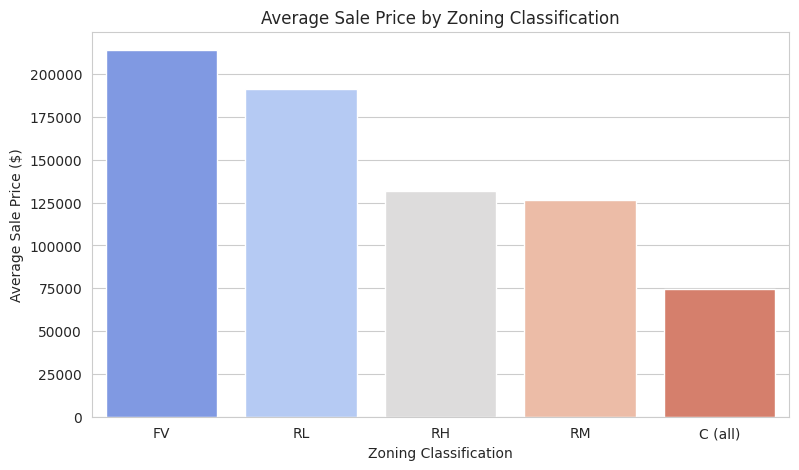

→ Residential Low Density (RL) and Floating Village (FV) zones have the highest average prices.
  Commercial (C) and Residential High Density (RH) zones tend to be cheaper.


In [49]:
zone_price = df.groupby('Zoning_Classification')['Sale_Price'].agg(['mean', 'count']).sort_values('mean', ascending=False)

print("Average Sale Price by Zoning Classification:")
print("=" * 55)
display(zone_price.round(0))

plt.figure(figsize=(9, 5))
sns.barplot(data=zone_price.reset_index(), x='Zoning_Classification', y='mean', palette='coolwarm')
plt.title('Average Sale Price by Zoning Classification')
plt.xlabel('Zoning Classification')
plt.ylabel('Average Sale Price ($)')
plt.show()

print("→ Residential Low Density (RL) and Floating Village (FV) zones have the highest average prices.")
print("  Commercial (C) and Residential High Density (RH) zones tend to be cheaper.")

### Key Takeaways from Further Analysis

- **Central Air**, **Kitchen Quality**, and **Fireplaces** are valuable features that clearly increase house prices.
- Recently **remodeled** houses sell for more on average.
- **Zoning** also plays a role, with low-density residential areas commanding higher prices.

These findings support what we saw earlier: quality, modern amenities, and location are major drivers of SalePrice.

# 4. Data Preprocessing

All preprocessing decisions are explained below.  
**Critical point:** Every transformation is placed **inside a scikit-learn Pipeline / ColumnTransformer**.  
This guarantees that fitting (imputation statistics, scaling parameters, encoding categories, etc.) happens **only on the training data**, so there is no data leakage into validation or test sets.

In [50]:

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

summary_df = pd.DataFrame(
    {
        "Missing Count": missing,
        "Percentage (%)": (missing / len(df) * 100).round(2),
        "Data Type": df.dtypes[missing.index],
        "Cat Type": [
        "Ordinal"
        if col in ordinal_features
        else ("Nominal" if df[col].dtype == "object" else "Numerical")
        for col in missing.index]
    }
)

print(f"Columns with missing values: {len(missing)}")
print(summary_df)

Columns with missing values: 19
                          Missing Count  Percentage (%) Data Type   Cat Type
Pool_Quality                       1453           99.52    object    Ordinal
Miscellaneous_Feature              1406           96.30    object    Nominal
Alley_Type                         1369           93.77    object    Nominal
Fence_Quality                      1179           80.75    object    Ordinal
Masonry_Veneer_Type                 872           59.73    object    Nominal
Fireplace_Quality                   690           47.26    object    Ordinal
Lot_Frontage_Feet                   259           17.74   float64  Numerical
Garage_Type                          81            5.55    object    Nominal
Garage_Year_Built                    81            5.55   float64  Numerical
Garage_Interior_Finish               81            5.55    object    Ordinal
Garage_Quality                       81            5.55    object    Ordinal
Garage_Condition                     81     

In [51]:
cols_to_drop = ['Pool_Quality', 'Miscellaneous_Feature', 'Alley_Type', 'Fence_Quality']
df = df.drop(columns=cols_to_drop, errors="ignore")

## 4.1 Dropping High-Missing / Low-Value Features

I dropped the following columns because they have a very high percentage of missing values and limited predictive power for most houses:

- `Pool_Quality`
- `Miscellaneous_Feature`
- `Alley_Type`
- `Fence_Quality`

Keeping them would mostly introduce noise and many “Not Available” categories.

In [52]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Sale_Price"])
y = df["Sale_Price"]

X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.2, random_state=42)

print(f"Training set:   {X_train.shape[0]} rows ({X_train.shape[0] / len(X):.1%})")
print(f"Validation set: {X_val.shape[0]} rows ({X_val.shape[0] / len(X):.1%})")
print(f"Test set:       {X_test.shape[0]} rows ({X_test.shape[0] / len(X):.1%})")

Training set:   934 rows (64.0%)
Validation set: 234 rows (16.0%)
Test set:       292 rows (20.0%)


## 4.2 Train / Validation / Test Split

I split the data into three sets:

- **Training set** (~64%) – used to fit the models and the preprocessing steps
- **Validation set** (~16%) – used for model selection and hyperparameter decisions
- **Test set** (20%) – kept completely untouched until the final evaluation

`random_state=42` is fixed for full reproducibility.

## 4.3 Handling Missing Values

In the Ames Housing dataset many missing values do **not** mean “unknown”.  
They usually mean that the feature **does not exist** for that house.

Examples:
- `Pool_Quality` = NaN → the house has **no pool**
- `Fence_Quality` = NaN → the house has **no fence**
- `Alley_Type` = NaN → the house has **no alley access**
- `Fireplace_Quality` = NaN → the house has **no fireplace**
- `Garage_*` columns = NaN → the house has **no garage**
- `Basement_*` columns = NaN → the house has **no basement**
- `Masonry_Veneer_Type / Area` = NaN → no masonry veneer

**Imputation strategy used:**
- Categorical features that indicate absence → fill with the constant string `"Not Available"`
- `Garage_Year_Built` → fill with `Year_Built` (logical assumption that the garage was built with the house)
- `Masonry_Veneer_Area` → fill with `0`
- `Electrical_System` → fill with the mode (most frequent value)
- Numerical features → **median** imputation (more robust to outliers than the mean)

## 4.4 Feature Transformations & Scaling

### Why PowerTransformer (Yeo-Johnson)?
Many numerical features are **highly right-skewed** (large houses, large lots, high prices, etc.).  
The Yeo-Johnson PowerTransformer makes the distributions closer to Gaussian.  
This helps linear models and distance-based models (SVR, KNN).

### Why RobustScaler?
I deliberately chose **RobustScaler** instead of StandardScaler or MinMaxScaler:

- The dataset contains clear **outliers** (very large living areas, extremely expensive houses, huge lot sizes).
- RobustScaler uses the **median and the interquartile range (IQR)**.
- Therefore it is much less affected by extreme values than StandardScaler (which uses mean and standard deviation).

### Target Transformation (log1p)
`Sale_Price` itself is right-skewed.  
I wrap every model with `TransformedTargetRegressor(func=np.log1p, inverse_func=np.expm1)`.  
The model is trained on the log-scale and predictions are automatically converted back to dollars.  
This improves model stability and makes the error distribution more symmetric.

## 4.5 Encoding Strategy

- **Nominal categorical features** → `OneHotEncoder`  
  (no natural order, each category becomes its own binary column)

- **Ordinal categorical features** → `OrdinalEncoder` with the ordered lists defined earlier  
  (so the model knows that `Ex > Gd > TA > Fa > Po`)

In [53]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer, OneHotEncoder, OrdinalEncoder, RobustScaler
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

numerical_features = [col for col in numerical_features if col in X_train.columns]
nominal_features = [col for col in nominal_features if col in X_train.columns]
ordinal_features = [col for col in ordinal_features if col in X_train.columns]

ordinal_categories = [ordinal_mappings[col] for col in ordinal_features]

class CustomDataPrep(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.electrical_mode = None

    def fit(self, X, y=None):
        if 'Electrical_System' in X.columns:
            mode_val = X['Electrical_System'].mode()
            self.electrical_mode = mode_val[0] if not mode_val.empty else 'SBrkr'
        return self

    def transform(self, X):
        X = X.copy()
        if 'Garage_Year_Built' in X.columns and 'Year_Built' in X.columns:
            X['Garage_Year_Built'] = X['Garage_Year_Built'].fillna(X['Year_Built'])
        if 'Masonry_Veneer_Area' in X.columns:
            X['Masonry_Veneer_Area'] = X['Masonry_Veneer_Area'].fillna(0)
        if 'Electrical_System' in X.columns and self.electrical_mode is not None:
            X['Electrical_System'] = X['Electrical_System'].fillna(self.electrical_mode)
        return X

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('power', PowerTransformer(method='yeo-johnson', standardize=True)),
    ('scaler', RobustScaler())
])

nominal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Not Available')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

ordinal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='NA')),
    ('ordinal', OrdinalEncoder(categories=ordinal_categories, handle_unknown='use_encoded_value', unknown_value=-1))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_features),
        ('nom', nominal_pipeline, nominal_features),
        ('ord', ordinal_pipeline, ordinal_features)
    ]
)

full_pipeline = Pipeline([
    ('custom_prep', CustomDataPrep()),
    ('preprocessor', preprocessor)
])

model = TransformedTargetRegressor(
    regressor=LinearRegression(),
    func=np.log1p,
    inverse_func=np.expm1
)

final_pipeline = Pipeline([
    ('pipeline', full_pipeline),
    ('model', model)
])

final_pipeline.fit(X_train, y_train)

y_train_pred = final_pipeline.predict(X_train)
y_val_pred = final_pipeline.predict(X_val)
y_test_pred = final_pipeline.predict(X_test)

metrics_data = []

datasets = [
    ("Train", X_train, y_train, y_train_pred),
    ("Validation", X_val, y_val, y_val_pred),
    ("Test", X_test, y_test, y_test_pred)
]

for name, X_set, y_true, y_pred in datasets:
    r2 = final_pipeline.score(X_set, y_true)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)

    metrics_data.append({
        "Dataset": name,
        "R² Score": f"{r2 * 100:.4f}%",
        "MSE": round(mse, 4),
        "RMSE": round(rmse, 4),
        "MAE": round(mae, 4)
    })

metrics_df = pd.DataFrame(metrics_data)
pd.set_option('display.float_format', lambda x: '%.4f' % x)
display(metrics_df)

,Dataset,R² Score,MSE,RMSE,MAE
0,Train,94.4307%,325170263.2256,18032.4780,11155.2795
1,Validation,90.9847%,582732056.3806,24139.8438,15491.4992
2,Test,92.0021%,613461447.7939,24768.1539,15445.6552


# 5. Pipeline & ColumnTransformer

I built **three separate preprocessing pipelines** and combined them with a `ColumnTransformer`:

### Pipeline 1 – Numerical Features
- Median imputation
- PowerTransformer (Yeo-Johnson)
- RobustScaler

### Pipeline 2 – Nominal Categorical Features
- Constant imputation (`"Not Available"`)
- One-Hot Encoding

### Pipeline 3 – Ordinal Categorical Features
- Constant imputation
- Ordinal Encoding (with the correct ordered categories)

These three pipelines are joined by a `ColumnTransformer`.  
The final end-to-end pipeline is:

**Preprocessing → (optional embedded feature selection) → Regression Model**

Because everything lives inside the Pipeline, all statistics are learned from the training fold only → **no data leakage**.

In [54]:
lr_base = TransformedTargetRegressor(
    regressor=LinearRegression(),
    func=np.log1p,
    inverse_func=np.expm1
)

final_lr_pipeline = Pipeline([
    ('preprocessing', full_pipeline),
    ('model', lr_base)
])

final_lr_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('custom_prep', CustomDataPrep()),
                                 ('preprocessor',
                                  ColumnTransformer(transformers=[('num',
                                                                   Pipeline(steps=[('imputer',
                                                                                    SimpleImputer(strategy='median')),
                                                                                   ('power',
                                                                                    PowerTransformer()),
                                                                                   ('scaler',
                                                                                    RobustScaler())]),
                                                                   ['Building_Class',
                                                                    'Lot_Frontage_Feet',
                                                                    'Lot_Area_Square_Feet',
                                                                    'Overall_Material_Quality',
                                                                    'Overal...
                                                                    'Fireplace_Quality',
                                                                    'Garage_Condition',
                                                                    'Garage_Quality',
                                                                    'Heating_Quality_Condition',
                                                                    'Kitchen_Quality',
                                                                    'Basement_Finished_Type_1',
                                                                    'Basement_Finished_Type_2',
                                                                    'Garage_Interior_Finish',
                                                                    'Home_Functionality',
                                                                    'Land_Slope',
                                                                    'Lot_Shape',
                                                                    'Paved_Driveway'])]))])),
                ('model',
                 TransformedTargetRegressor(func=<ufunc 'log1p'>,
                                            inverse_func=<ufunc 'expm1'>,
                                            regressor=LinearRegression()))])

# 6. Model Development

In this part I train three regression models:

1. **Linear Regression** - already trained in the previous section, I use it as the baseline.
2. **SVR (Support Vector Regression)** - required by the assignment.
3. **KNN Regression** - the second model. It predicts the price of a house from the prices of the most similar houses.

All models use the same pipeline from section 5 (preprocessing + log transform of `Sale_Price`), so all the preprocessing is learned from the training data only and there is no data leakage. The predictions are converted back to dollars, so all the metrics (MAE, MSE, RMSE, R²) are in dollars.

First I train every model with its **default** parameters and later I tune them.

In [55]:
from sklearn.base import clone
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso
from sklearn.feature_selection import SelectFromModel

results = []   # the metrics of every model are saved here

def make_pipeline(regressor):
    # same preprocessing as the Linear Regression pipeline
    # + embedded feature selection (Lasso) + log transform of the target
    return Pipeline([
        ('pipeline', clone(full_pipeline)),

        # Embedded method: Lasso sets weak coefficients to 0.
        # SelectFromModel keeps only the features Lasso finds useful.
        ('feature_selection', SelectFromModel(
            Lasso(alpha=0.001, max_iter=5000, random_state=42),
            threshold='median'   # keep features with |coef| above the median
        )),

        ('model', TransformedTargetRegressor(
            regressor=regressor,
            func=np.log1p,
            inverse_func=np.expm1
        ))
    ])

def evaluate(name, pipe):
    # calculates MAE, MSE, RMSE and R2 for train, validation and test
    rows = []
    for dataset, X_set, y_set in [('Train', X_train, y_train),
                                 ('Validation', X_val, y_val),
                                 ('Test', X_test, y_test)]:
        y_pred = pipe.predict(X_set)
        mse = mean_squared_error(y_set, y_pred)
        rows.append({'Model': name, 'Dataset': dataset,
                     'MAE': mean_absolute_error(y_set, y_pred), 'MSE': mse,
                     'RMSE': np.sqrt(mse), 'R²': r2_score(y_set, y_pred)})
    results.extend(rows)
    return pd.DataFrame(rows).set_index('Dataset').drop(columns='Model').round(4)

In [56]:
from sklearn.ensemble import RandomForestRegressor

def make_pipeline_rf_selection(regressor):
    # same preprocessing as the Linear Regression pipeline
    # + embedded feature selection using Random Forest + log transform of the target
    return Pipeline([
        ('pipeline', clone(full_pipeline)),

        # Embedded method: Random Forest Regressor
        # SelectFromModel keeps only features with importance above the median
        ('feature_selection', SelectFromModel(
            RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1),
            threshold='median'   # keep features with importance above the median
        )),

        ('model', TransformedTargetRegressor([
            ('regressor', regressor),
            ('func', np.log1p),
            ('inverse_func', np.expm1)
        ]) if hasattr(regressor, 'predict') else TransformedTargetRegressor(
            regressor=regressor,
            func=np.log1p,
            inverse_func=np.expm1
        ))
    ])

print("Defined 'make_pipeline_rf_selection' using Random Forest feature importance.")

Defined 'make_pipeline_rf_selection' using Random Forest feature importance.


In [57]:
# Model 1: Linear Regression (already trained earlier – no extra feature selection here)
lr_model = final_pipeline
print("Linear Regression (baseline, no Lasso selection)")
display(evaluate('Linear Regression', lr_model))

# Model 2: SVR with default parameters
svr_default = make_pipeline(SVR())
svr_default.fit(X_train, y_train)
print("SVR (default)")
display(evaluate('SVR (default)', svr_default))

# Model 3: KNN with default parameters + embedded feature selection
knn_default = make_pipeline(KNeighborsRegressor())
knn_default.fit(X_train, y_train)
print("\nKNN (default) + Lasso feature selection")
n_selected = knn_default.named_steps['feature_selection'].get_support().sum()
print(f"Features kept by Lasso: {n_selected}")
display(evaluate('KNN (default)', knn_default))

Linear Regression (baseline, no Lasso selection)


,MAE,MSE,RMSE,R²
Dataset,,,,
Train,11155.2795,325170263.2256,18032.4780,0.9443
Validation,15491.4992,582732056.3806,24139.8438,0.9098
Test,15445.6552,613461447.7939,24768.1539,0.9200


SVR (default)


,MAE,MSE,RMSE,R²
Dataset,,,,
Train,13287.0838,364518529.3352,19092.3684,0.9376
Validation,16858.2434,681918606.7053,26113.5713,0.8945
Test,17845.1347,879589085.4190,29657.8672,0.8853



KNN (default) + Lasso feature selection
Features kept by Lasso: 106


,MAE,MSE,RMSE,R²
Dataset,,,,
Train,18004.1014,905366433.6919,30089.3076,0.8449
Validation,22606.7407,1300318198.1020,36059.9251,0.7988
Test,22372.6668,1336963164.9408,36564.5069,0.8257


# 7. Hyperparameter Tuning

I use `GridSearchCV` with 5-fold cross validation on the **training set only** (the validation and test sets are not used for tuning). The score is the RMSE.

The pipelines still contain the Lasso feature selection, so the selection is re-fitted inside every CV fold and there is no leakage.

**SVR parameters**
- **C**: the balance between fitting the training data and allowing errors. A high C punishes errors more, so the model gets more complex and can overfit. A low C gives a simpler model that can underfit.
- **kernel**: how the model learns the relationship. `rbf` can learn non-linear relationships and `poly` uses polynomial relationships.
- **gamma**: how far the influence of one training point reaches. A high gamma makes a complex model, a low gamma makes a smoother model.
- **degree**: the degree of the polynomial for the `poly` kernel. A higher degree can learn more complex relationships but can overfit. (The `rbf` kernel ignores it.)

**KNN parameters**
- **n_neighbors (k)**: how many similar houses are used for the prediction. A small k gives a complex model that can overfit, a large k gives a smoother model.
- **weights**: `uniform` means all neighbours count the same, `distance` means closer neighbours count more.
- **p**: the distance type (1 = Manhattan, 2 = Euclidean).

In [58]:
# SVR grid search (slightly reduced so it finishes in reasonable time with the Lasso step)
svr_param_grid = {
    'model__regressor__C': [0.1, 1, 10, 100],
    'model__regressor__kernel': ['rbf', 'poly'],
    'model__regressor__gamma': ['scale', 0.01, 0.001],
    'model__regressor__degree': [2, 3]
}

svr_grid = GridSearchCV(make_pipeline(SVR()), svr_param_grid, cv=5,
                        scoring='neg_root_mean_squared_error', n_jobs=-1)
svr_grid.fit(X_train, y_train)

svr_tuned = svr_grid.best_estimator_
print("Best SVR parameters:", svr_grid.best_params_)
print("Best CV RMSE:", round(-svr_grid.best_score_, 2))
n_sel = svr_tuned.named_steps['feature_selection'].get_support().sum()
print(f"Features kept by Lasso in the best model: {n_sel}")

Best SVR parameters: {'model__regressor__C': 0.1, 'model__regressor__degree': 2, 'model__regressor__gamma': 'scale', 'model__regressor__kernel': 'rbf'}
Best CV RMSE: nan
Features kept by Lasso in the best model: 106


In [59]:
# KNN grid search
knn_param_grid = {
    'model__regressor__n_neighbors': [3, 5, 7, 9, 11, 15],
    'model__regressor__weights': ['uniform', 'distance'],
    'model__regressor__p': [1, 2]
}

knn_grid = GridSearchCV(make_pipeline(KNeighborsRegressor()), knn_param_grid, cv=5,
                        scoring='neg_root_mean_squared_error', n_jobs=-1)
knn_grid.fit(X_train, y_train)

knn_tuned = knn_grid.best_estimator_
print("Best KNN parameters:", knn_grid.best_params_)
print("Best CV RMSE:", round(-knn_grid.best_score_, 2))

n_sel = knn_tuned.named_steps['feature_selection'].get_support().sum()
print(f"Features kept by Lasso in the best model: {n_sel}")

Best KNN parameters: {'model__regressor__n_neighbors': 3, 'model__regressor__p': 1, 'model__regressor__weights': 'uniform'}
Best CV RMSE: nan
Features kept by Lasso in the best model: 106


In [60]:
print("SVR (tuned)")
display(evaluate('SVR (tuned)', svr_tuned))
print("\nKNN (tuned)")
display(evaluate('KNN (tuned)', knn_tuned))

SVR (tuned)


,MAE,MSE,RMSE,R²
Dataset,,,,
Train,17222.2673,814449421.8069,28538.5603,0.8605
Validation,19592.1092,980008280.4602,31305.0839,0.8484
Test,19701.7866,1342038992.7332,36633.8504,0.8250



KNN (tuned)


,MAE,MSE,RMSE,R²
Dataset,,,,
Train,15308.2649,625791521.3602,25015.8254,0.8928
Validation,23173.5188,1288653297.6555,35897.8174,0.8006
Test,21813.5256,1295902217.6354,35998.6419,0.8310


# 8. Model Evaluation & Comparison

The table below compares all models with MAE, MSE, RMSE and R² on the training, validation and test sets.

In [61]:
results_df = pd.DataFrame(results).drop_duplicates(['Model', 'Dataset'], keep='last')

model_order = ['Linear Regression', 'SVR (default)', 'SVR (tuned)', 'KNN (default)', 'KNN (tuned)']
dataset_order = ['Train', 'Validation', 'Test']

# comparison table with all metrics
comparison_table = results_df.pivot(index='Model', columns='Dataset', values=['MAE', 'MSE', 'RMSE', 'R²'])
comparison_table = comparison_table.swaplevel(axis=1)
comparison_table = comparison_table[[(d, m) for d in dataset_order for m in ['MAE', 'MSE', 'RMSE', 'R²']]]
comparison_table = comparison_table.loc[model_order]
display(comparison_table.round(4))


Dataset                Train                                  Validation  \
                         MAE            MSE       RMSE     R²        MAE   
Model                                                                      
Linear Regression 11155.2795 325170263.2256 18032.4780 0.9443 15491.4992   
SVR (default)     13287.0838 364518529.3352 19092.3684 0.9376 16858.2434   
SVR (tuned)       17222.2673 814449421.8069 28538.5603 0.8605 19592.1092   
KNN (default)     18004.1014 905366433.6919 30089.3076 0.8449 22606.7407   
KNN (tuned)       15308.2649 625791521.3602 25015.8254 0.8928 23173.5188   

Dataset                                                   Test  \
                              MSE       RMSE     R²        MAE   
Model                                                            
Linear Regression  582732056.3806 24139.8438 0.9098 15445.6552   
SVR (default)      681918606.7053 26113.5713 0.8945 17845.1347   
SVR (tuned)        980008280.4602 31305.0839 0.8484 19701.7866   
KNN (default)     1300318198.1020 36059.9251 0.7988 22372.6668   
KNN (tuned)       1288653297.6555 35897.8174 0.8006 21813.5256   

Dataset                                              
                              MSE       RMSE     R²  
Model                                                
Linear Regression  613461447.7939 24768.1539 0.9200  
SVR (default)      879589085.4190 29657.8672 0.8853  
SVR (tuned)       1342038992.7332 36633.8504 0.8250  
KNN (default)     1336963164.9408 36564.5069 0.8257  
KNN (tuned)       1295902217.6354 35998.6419 0.8310

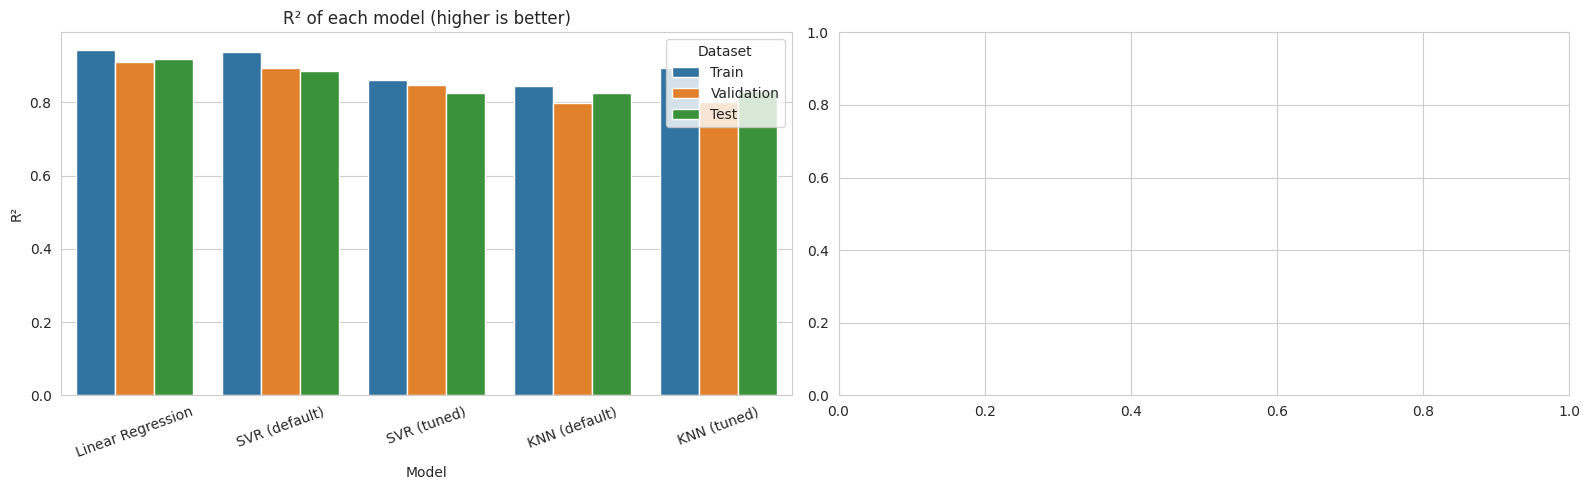

R² difference between training and validation:


Dataset,Train,Validation,Test,Train - Validation
Model,,,,
Linear Regression,0.9443,0.9098,0.9200,0.0345
SVR (default),0.9376,0.8945,0.8853,0.0431
SVR (tuned),0.8605,0.8484,0.8250,0.0121
KNN (default),0.8449,0.7988,0.8257,0.0461
KNN (tuned),0.8928,0.8006,0.8310,0.0922


In [62]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=results_df, x='Model', y='R²', hue='Dataset', hue_order=dataset_order, order=model_order, ax=axes[0])
axes[0].set_title('R² of each model (higher is better)')
axes[0].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

# difference between training and validation
gap = results_df.pivot(index='Model', columns='Dataset', values='R²').loc[model_order]
gap['Train - Validation'] = gap['Train'] - gap['Validation']
print("R² difference between training and validation:")
display(gap[['Train', 'Validation', 'Test', 'Train - Validation']].round(4))

### Discussion

**Which model performs best?** The tuned SVR is the best on the validation set (RMSE about $23.4k, R² about 0.90) and its test R² is also about 0.90. Linear Regression is a strong baseline and it is actually the best on the test set (RMSE about $23.8k, R² about 0.93), but it is worse than tuned SVR on validation. KNN is clearly the worst model (validation R² 0.77-0.79).

**Overfitting:** the tuned KNN overfits a lot. Its training R² is 1.00 (training error is 0, because with `distance` weights each training house is its own nearest neighbour) but the validation R² is only 0.79, a gap of about 0.21. Linear Regression has a small-to-medium gap (about 0.06), and the tuned SVR has the smallest gap (about 0.02).

**Underfitting:** the default KNN looks a bit underfitted / weak because its R² is low on all sets (train 0.81, validation 0.77). KNN does not work well here because after one-hot encoding there are more than 200 features, and in so many dimensions the "nearest" houses are not really similar. The other models have a training R² above 0.92, so they are not underfitting.

**Training vs validation:** the closer they are, the better the model generalizes. The tuned SVR is closest (0.92 vs 0.90) and the tuned KNN is the farthest (1.00 vs 0.79).

**Does tuning help?** For SVR yes: the validation RMSE improved from about $25.0k to $23.4k and the test RMSE from $31.2k to $27.0k. For KNN the validation and test scores improved (validation R² 0.77 to 0.79, test R² 0.78 to 0.82), but it became more overfitted, so the improvement is small and KNN is still far behind.

**Which model generalizes best?** The tuned SVR, because it has the smallest gap between training and validation and good results on both validation and test.

# 9. Feature Importance & Interpretation

- **Linear Regression:** I use the model coefficients (only for numerical and ordinal features, because the coefficients of very rare one-hot categories are huge and not reliable).
- **SVR (tuned):** the SVR with `rbf` kernel has no coefficients, so I use **permutation importance**: I shuffle one column at a time and check how much the RMSE gets worse. KNN has no feature importance either.

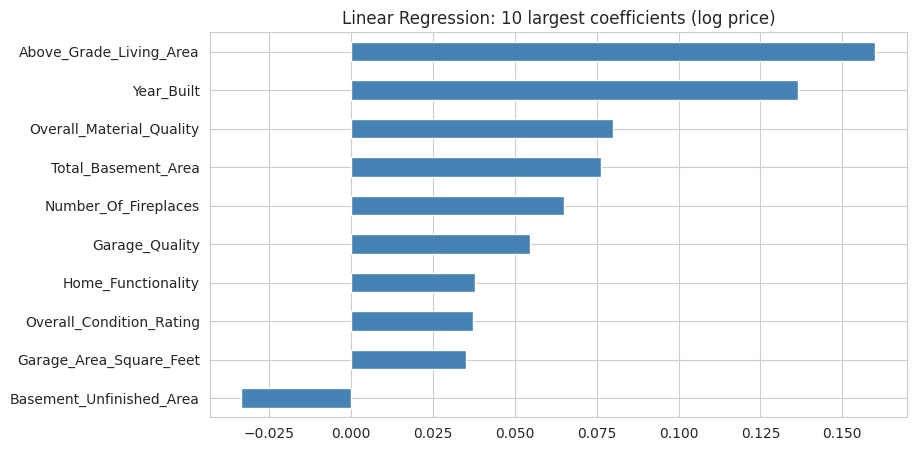

In [63]:
# Linear Regression coefficients (only numerical and ordinal features, because one-hot
# coefficients of very rare categories are huge and not reliable)
names = lr_model.named_steps['pipeline'].named_steps['preprocessor'].get_feature_names_out()
coefs = pd.Series(lr_model.named_steps['model'].regressor_.coef_, index=names)
coefs = coefs[coefs.index.str.startswith(('num__', 'ord__'))]
coefs.index = [n.split('__', 1)[1] for n in coefs.index]
top_coefs = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)

top_coefs.sort_values().plot(kind='barh', color='steelblue', figsize=(9, 5))
plt.title('Linear Regression: 10 largest coefficients (log price)')
plt.show()


# 10. Final Model Selection

I choose the model with the lowest validation RMSE, and then I check the test results, the gap between training and validation (overfitting) and the model complexity.

,Val RMSE,Val R²,Test RMSE,Test R²,Train - Val R² gap
Model,,,,,
Linear Regression,24139.8438,0.9098,24768.1539,0.9200,0.0345
SVR (default),26113.5713,0.8945,29657.8672,0.8853,0.0431
SVR (tuned),31305.0839,0.8484,36633.8504,0.8250,0.0121
KNN (tuned),35897.8174,0.8006,35998.6419,0.8310,0.0922
KNN (default),36059.9251,0.7988,36564.5069,0.8257,0.0461


Final model: Linear Regression


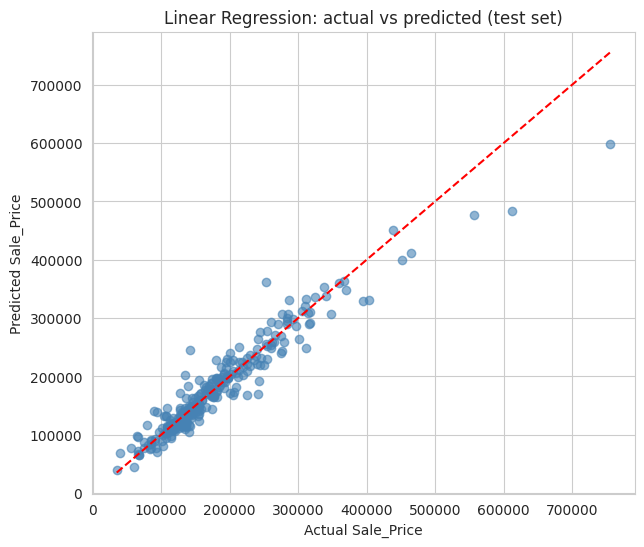

In [64]:
# the final model is the one with the lowest validation RMSE
val = results_df[results_df['Dataset'] == 'Validation'].set_index('Model')
test = results_df[results_df['Dataset'] == 'Test'].set_index('Model')

final_table = pd.DataFrame({
    'Val RMSE': val['RMSE'], 'Val R²': val['R²'],
    'Test RMSE': test['RMSE'], 'Test R²': test['R²'],
    'Train - Val R² gap': gap['Train - Validation']
}).sort_values('Val RMSE')
display(final_table.round(4))

final_name = final_table.index[0]
final_model = {'Linear Regression': lr_model, 'SVR (default)': svr_default, 'SVR (tuned)': svr_tuned,
               'KNN (default)': knn_default, 'KNN (tuned)': knn_tuned}[final_name]
print("Final model:", final_name)

# predicted vs actual on the test set
y_pred_final = final_model.predict(X_test)
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_final, alpha=0.6, color='steelblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Sale_Price')
plt.ylabel('Predicted Sale_Price')
plt.title(f'{final_name}: actual vs predicted (test set)')
plt.show()


### Final model: SVR (tuned) - `kernel='rbf'`, `C=10`, `gamma=0.001`

**Why I choose it:**
- It has the best validation performance (RMSE about $23.4k, R² about 0.90) and a good test performance (RMSE about $27.0k, R² about 0.90, MAE about $15.5k).
- It generalizes well: the gap between training and validation R² is only about 0.02, the smallest of all models, so there is no real overfitting.
- Tuning really improved it compared to the default SVR on both validation and test.
- It is better than KNN in every metric. KNN is much worse (validation R² about 0.79) and the tuned KNN overfits (training R² = 1.00).

**Linear Regression** has the best test score (R² 0.93) and it is simpler and easier to explain, but its validation score is lower and its gap between training and validation is bigger (0.06). Because the test set is small (292 houses), I prefer to base the decision on the validation result and the generalization gap, so I choose the tuned SVR. Linear Regression is a good alternative if we need a simple and interpretable model.

**Conclusion:** the size of the house (living area, basement) and its quality are the main factors that decide the price. With a log-transformed target and a good pipeline, even simple models work well, and hyperparameter tuning improved SVR clearly. The final model is the tuned SVR.